# INF161 – Prosjekt: `persona_survey.csv`

**Eirik Aarrestad**

Datasettet består av 10 000 personaer, hvor 9 000 er ekte personer og 1 000 er
fiktive figurer. En språkmodell har besvart 62 spørsmål for hver persona, og svarene
representerer modellens inntrykk av personen eller figuren, ikke nødvendigvis
faktiske egenskaper eller meninger. Vi studerer altså hva en språkmodell tror om
historien.

Notebooken er én sammenhengende pipeline fra innlesing av `persona_survey.csv` til de
endelige skårene og figurene. Den skal kjøres fra topp til bunn (*Restart & Run All*)
og gir de samme tallene hver gang.

| Del | Innhold | Seksjoner |
|---|---|---|
| **Oppsett** | Moduler, versjoner, tilfeldighetsfrø og felles definisjoner | 0 |
| **Del 1 – Utforskende dataanalyse** | Datavalidering, splitt, statistisk beskrivelse av alle variabler, fordelinger, sammenhenger, gruppeforskjeller og tekstmønstre | 1–7 |
| **Del 2 – Prediktiv modellering** | Oppgave A: fødselsår `born` (regresjon). Oppgave B: `occupation_category` (klassifikasjon) | 8–12 |

Figurene lagres i mappen `img/` og brukes i rapporten.

## 0. Oppsett

### 0.1 Moduler, versjoner og tilfeldighetsfrø

Alle moduler importeres her. Vi skriver ut versjonene slik at analysen kan
gjenskapes med de samme bibliotekene (de står også i `requirements.txt`).

In [ ]:
# Import necessary libraries
import os
import sys
import scipy
import sklearn
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDRegressor, SGDClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, median_absolute_error

# Fixed seed so that the split and all models are reproducible
RANDOM_STATE = 42

# Show more columns when printing tables
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# All figures are saved here and reused in the report
os.makedirs("img", exist_ok=True)

print("Python      ", sys.version.split()[0])
for lib in [np, pd, scipy, sklearn, matplotlib]:
    print(f"{lib.__name__:12s}", lib.__version__)

Python       3.12.14
numpy        2.5.2
pandas       3.0.5
scipy        1.18.1
sklearn      1.9.0
matplotlib   3.11.1


### 0.2 Innlesing av data

In [2]:
# Read the full dataset
df_full = pd.read_csv("./persona_survey.csv")

df_full.head()

,persona_id,name,type,occupation,occupation_category,gender,born,died,born_city,born_country,fame_rank,sections_ok,big_five.EXT1,big_five.EXT2,big_five.EXT5,...,personal.legacy_or_happiness,personal.favorite_thing_about_bergen,personal.favorite_data_science_fact,personal.life_satisfaction,personal.favorite_animal,personal.last_meal,personal.favorite_season,moral_exchange_rates.cats_per_human,moral_exchange_rates.dogs_per_human,moral_exchange_rates.chickens_per_human,moral_exchange_rates.cows_per_human,moral_exchange_rates.trees_per_human,moral_exchange_rates.cats_per_dog,moral_exchange_rates.dogs_per_cow,moral_exchange_rates.chickens_per_cow
0,f0000,Isaac Newton,real,physicist,science & medicine,M,1643.0,1726.0,Woolsthorpe-by-Colsterworth,United Kingdom,1,5,1,5,1,...,a lasting legacy,The dramatic geological formations and rainfal...,The ability to discern universal laws from the...,9.0,Falcon,Roasted pheasant with rosemary,autumn,1000000.0,500000.0,1.000000e+07,250000.00,100000000.0,2.0,2.0,40.0
1,f0001,Donald Trump,real,politician,politics & rule,M,1946.0,NaN,Queens,United States,2,5,5,1,5,...,a lasting legacy,"The beautiful mountains and the strong, indepe...",Data can be manipulated by the radical left to...,10.0,Eagle,Cheeseburger and fries,summer,1000000.0,500000.0,1.000000e+07,1000000.00,10000000.0,2.0,5.0,100.0
2,f0002,Genghis Khan,real,military personnel,military,M,1162.0,1227.0,Khentii Mountains,Mongolia,3,5,2,4,2,...,a lasting legacy,"The rugged mountains and the harsh, enduring c...",The ability to predict the movements of an ent...,10.0,Wolf,Roasted mutton and fermented mare's milk,autumn,1000000.0,500000.0,1.000000e+04,100.00,1000000.0,2.0,5000.0,1000.0
3,f0003,Cleopatra,real,politician,politics & rule,F,-69.0,-30.0,Alexandria,Egypt,4,5,5,1,5,...,a lasting legacy,The dramatic fjords and misty atmosphere.,The ability to predict the movements of empire...,9.0,Leopard,Roasted peacock with honey and figs,summer,0.5,0.1,1.000000e-03,0.01,1000.0,5.0,10.0,50.0
4,f0004,Mahatma Gandhi,real,social activist,other,M,1869.0,1948.0,Porbandar,India,5,5,1,4,2,...,a lasting legacy,The serene mountains and the purity of the rai...,The ability to find truth and patterns amidst ...,9.0,Cow,Khichdi,spring,1000000.0,1000000.0,1.000000e+06,100.00,1000000.0,1.0,10.0,100.0


### 0.3 Felles definisjoner

Datakatalogen deler de 62 svarkolonnene inn i fem seksjoner. Her definerer vi
én gang hvilke kolonner som hører til hvilken gruppe, og hvordan Big Five og det
politiske kompasset skåres. Definisjonene brukes både i den utforskende analysen
og i modelleringen.

In [ ]:
# The survey answers are the only columns named "section.field" with one of these sections
SECTIONS = ("big_five.", "political_compass.", "values.", "personal.", "moral_exchange_rates.")
survey_cols = [c for c in df_full.columns if c.startswith(SECTIONS)]

# Political compass: no neutral option, so the scale skips 0
score_map = {"strongly disagree": -2, "disagree": -1, "agree": 1, "strongly agree": 2}

economic_left = ["political_compass.econ_redistribute_wealth", "political_compass.econ_public_services", "political_compass.econ_tax_the_wealthy"]
economic_right = ["political_compass.econ_free_markets", "political_compass.econ_personal_responsibility", "political_compass.econ_welfare_dependency"]
social_libertarian = ["political_compass.soc_immigration_benefits", "political_compass.soc_legalize_drugs", "political_compass.soc_embrace_changing_norms"]
social_authoritarian = ["political_compass.soc_strong_leader", "political_compass.soc_harsh_punishment",  "political_compass.soc_traditional_values_laws"]

political_cols = economic_left + economic_right + social_libertarian + social_authoritarian

# Big Five: the four items belonging to each trait
big_five_traits = {
    "extraversion": ["big_five.EXT1", "big_five.EXT2", "big_five.EXT5", "big_five.EXT10"],
    "neuroticism": ["big_five.EST1", "big_five.EST2", "big_five.EST3", "big_five.EST10"],
    "agreeableness": ["big_five.AGR1", "big_five.AGR2", "big_five.AGR4", "big_five.AGR5"],
    "conscientiousness": ["big_five.CSN1", "big_five.CSN2", "big_five.CSN5", "big_five.CSN8"],
    "openness": ["big_five.OPN2", "big_five.OPN3", "big_five.OPN6", "big_five.OPN9"],
}
big_five_cols = [item for items in big_five_traits.values() for item in items]

# Items marked (R) in the data catalogue: a high answer means LITTLE of the trait
reversed_items = ["big_five.EXT2", "big_five.EXT10", "big_five.EST2",
                  "big_five.AGR1", "big_five.AGR5", "big_five.CSN2", "big_five.CSN8",
                  "big_five.OPN2", "big_five.OPN6"]

# Values spanning many orders of magnitude, which we log-transform
log_cols = [c for c in survey_cols if c.startswith("moral_exchange_rates.")] + ["values.random_people_per_me"]

# Other numerical answers
plain_numeric = ["values.dictator_give_pct", "values.p_god_exists", "values.p_living_in_simulation",
                 "personal.self_described_iq", "personal.height_cm", "personal.weight_kg", "personal.life_satisfaction"]

# Categorical answers with a fixed set of options
categorical_cols = ["personal.favorite_color", "personal.favorite_season", "personal.legacy_or_happiness",
                    "values.friend_crime_testify", "values.child_quality_most_important", "values.free_will", "values.wants_to_live_forever"]

# Free-text answers
text_columns = ["personal.favorite_person", "personal.favorite_book", "personal.favorite_painting",
                "personal.favorite_animal", "personal.last_meal", "personal.favorite_thing_about_bergen", "personal.favorite_data_science_fact"]

# Every survey column belongs to exactly one group
groups = big_five_cols + political_cols + log_cols + plain_numeric + categorical_cols + text_columns
assert sorted(groups) == sorted(survey_cols)
print("Antall svarkolonner:", len(survey_cols))
print(f"Big Five: {len(big_five_cols)}, politisk kompass: {len(political_cols)}, "
      f"log-numeriske: {len(log_cols)}, andre numeriske: {len(plain_numeric)}, "
      f"kategoriske: {len(categorical_cols)}, fritekst: {len(text_columns)}")

Antall svarkolonner: 62
Big Five: 20, politisk kompass: 12, log-numeriske: 9, andre numeriske: 7, kategoriske: 7, fritekst: 7


# Del 1 – Utforskende dataanalyse

Vi starter med å validere datasettet: størrelse, datatyper, gyldige verdier,
duplikater og manglende data. Deretter deler vi i trenings-, validerings- og
testsett, og gjør resten av analysen **kun på treningssettet**: en statistisk
beskrivelse av alle variablene, fordelinger, korrelasjoner, gruppeforskjeller og
mønstre i tekstsvarene.

## 1. Datavalidering

Valideringen gjøres på **hele** datasettet. Den sjekker bare datakvalitet og
påvirker ingen modellvalg, så den lekker ikke informasjon fra testsettet.

### 1.1 Størrelse, duplikater og unike identifikatorer

In [4]:
print("Antall rader og kolonner:", df_full.shape)

# Identical rows and unique ids
print("Antall dupliserte rader:", df_full.duplicated().sum())
print("Antall unike persona_id:", df_full["persona_id"].nunique())

# The data catalogue says 24 names are used by more than one persona
print("Navn brukt av mer enn én persona:", (df_full["name"].value_counts() > 1).sum())

print("\nFordeling av type:")
print(df_full["type"].value_counts())

Antall rader og kolonner: (10000, 74)
Antall dupliserte rader: 0
Antall unike persona_id: 10000
Navn brukt av mer enn én persona: 24

Fordeling av type:
type
real         9000
fictional    1000
Name: count, dtype: int64


Det er ingen dupliserte rader, og `persona_id` er unik. Som datakatalogen sier,
brukes noen navn av flere personaer, så vi kobler aldri på `name`.

### 1.2 Datatyper

Vi sjekker at hver svarkolonne har en datatype som passer til gruppen den tilhører:
numeriske svar skal være tall, og kategoriske svar og fritekst skal være tekst.

In [5]:
# Data types of the survey answers
print(df_full[survey_cols].dtypes.value_counts())

# The numerical groups should only contain numbers
not_numeric = [c for c in big_five_cols + plain_numeric + log_cols if not pd.api.types.is_numeric_dtype(df_full[c])]
print("\nNumeriske spørsmål som ikke er lagret som tall:", not_numeric)
print("Datatype for wants_to_live_forever:", df_full["values.wants_to_live_forever"].dtype)

str        25
int64      20
float64    16
object      1
Name: count, dtype: int64

Numeriske spørsmål som ikke er lagret som tall: []
Datatype for wants_to_live_forever: object


Alle numeriske svar er tall (`int64` eller `float64`). `float64` skyldes at
kolonnene har manglende verdier. De kategoriske svarene og fritekstene er tekst.
Unntaket er `values.wants_to_live_forever`, som har True/False og NaN og derfor
er `object`. Den behandles som kategorisk.

### 1.3 Gyldige verdier

Datakatalogen sier hvilke verdier hvert spørsmål kan ha. Vi sammenligner minste og
største verdi for de numeriske spørsmålene, og hvilke svaralternativer som brukes i
de kategoriske, med katalogen.

In [6]:
# Smallest and largest answer for the numerical questions, to compare with the data catalogue
df_full[big_five_cols + plain_numeric + log_cols].agg(["min", "max"]).T

,min,max
big_five.EXT1,1.000000e+00,5.000000e+00
big_five.EXT2,1.000000e+00,5.000000e+00
big_five.EXT5,1.000000e+00,5.000000e+00
big_five.EXT10,1.000000e+00,5.000000e+00
big_five.EST1,1.000000e+00,5.000000e+00
big_five.EST2,1.000000e+00,5.000000e+00
big_five.EST3,1.000000e+00,5.000000e+00
big_five.EST10,1.000000e+00,5.000000e+00
big_five.AGR1,1.000000e+00,5.000000e+00
big_five.AGR2,1.000000e+00,5.000000e+00


In [51]:
# All answer options used in the categorical questions, to compare with the data catalogue
print("Politisk kompass:", sorted(pd.unique(df_full[political_cols].values.ravel())))
for col in categorical_cols:
    print(f"{col}:", sorted(df_full[col].dropna().astype(str).unique()))

Politisk kompass: ['agree', 'disagree', 'strongly agree', 'strongly disagree']
personal.favorite_color: ['black', 'blue', 'brown', 'gold', 'green', 'orange', 'pink', 'purple', 'red', 'silver', 'white', 'yellow']
personal.favorite_season: ['autumn', 'spring', 'summer', 'winter']
personal.legacy_or_happiness: ['a happy life', 'a lasting legacy']
values.friend_crime_testify: ['protect my friend', 'testify honestly']
values.child_quality_most_important: ['hard work', 'imagination', 'independence', 'obedience', 'religious faith', 'thrift', 'tolerance and respect']
values.free_will: ["don't know", 'no', 'yes']
values.wants_to_live_forever: ['False', 'True']


Alle svar ligger innenfor de lovlige verdiene i datakatalogen: Big Five 1–5,
sannsynligheter 0–100, IQ 40–250, livstilfredshet 0–10, og bare de oppgitte
svaralternativene i de kategoriske spørsmålene. Noen verdier er likevel
**urealistiske**: høyde fra 1 til 500 cm, vekt opp til 2000 kg og vekslingskurser opp
til $10^9$. Vi sjekker hvem som har dem.

In [8]:
# Who gives the extreme height and weight answers?
extreme = (df_full["personal.height_cm"] < 100) | (df_full["personal.height_cm"] > 250) | (df_full["personal.weight_kg"] > 300)
print("Antall personaer med ekstrem høyde eller vekt:", extreme.sum())
print(df_full.loc[extreme, "type"].value_counts())
df_full.loc[extreme, ["name", "type", "personal.height_cm", "personal.weight_kg"]].head(8)

Antall personaer med ekstrem høyde eller vekt: 88
type
fictional    86
real          2
Name: count, dtype: int64


,name,type,personal.height_cm,personal.weight_kg
3407,Robert Wadlow,real,272.0,140.0
6004,Albert the Bear,real,220.0,350.0
9000,Mickey Mouse,fictional,91.0,18.0
9011,Hulk,fictional,254.0,500.0
9020,Minnie Mouse,fictional,91.0,15.0
9028,Loch Ness Monster,fictional,500.0,2000.0
9038,Yoda,fictional,94.0,45.0
9053,Bilbo Baggins,fictional,91.0,56.0


86 av de 88 ekstreme verdiene tilhører fiktive figurer, som Mickey Mouse (91 cm),
Hulk (254 cm, 500 kg) og Loch Ness-uhyret (500 cm, 2000 kg), der svaret er rimelig
*innenfor* fiksjonen. De to ekte er Robert Wadlow, verdens høyeste menneske
(272 cm), og en bjørn. Begge svarene er faktisk riktige. Det er språkmodellens svar og
ikke en feil i dataene, så vi **beholder** dem. I modelleringen bruker vi metoder
som tåler dem: log-transformasjon av vekslingskursene, og trebaserte modeller som
bare deler opp variablene i intervaller.

### 1.4 Manglende data

Vi undersøker hvor mye som mangler, og om det mangler tilfeldig eller systematisk.

In [9]:
missing = df_full.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

# Missing values per column, and how many of them are fictional personas
missing_table = pd.DataFrame({
    "mangler": missing,
    "andel (%)": (100 * missing / len(df_full)).round(2),
    "av dem fiktive": [df_full.loc[df_full[c].isna(), "type"].eq("fictional").sum() for c in missing.index],
})
missing_table

,mangler,andel (%),av dem fiktive
died,2230,22.30,961
born_city,501,5.01,36
born_country,324,3.24,36
personal.favorite_person,47,0.47,31
occupation,36,0.36,35
occupation_category,36,0.36,35
born,35,0.35,35
gender,35,0.35,35
personal.favorite_painting,25,0.25,11
personal.favorite_book,24,0.24,17


In [10]:
# sections_ok counts valid sections: 5 is complete for real personas, 6 for fictional ones
pd.crosstab(df_full["sections_ok"], df_full["type"])

type,fictional,real
sections_ok,,
4,0,5
5,53,8995
6,947,0


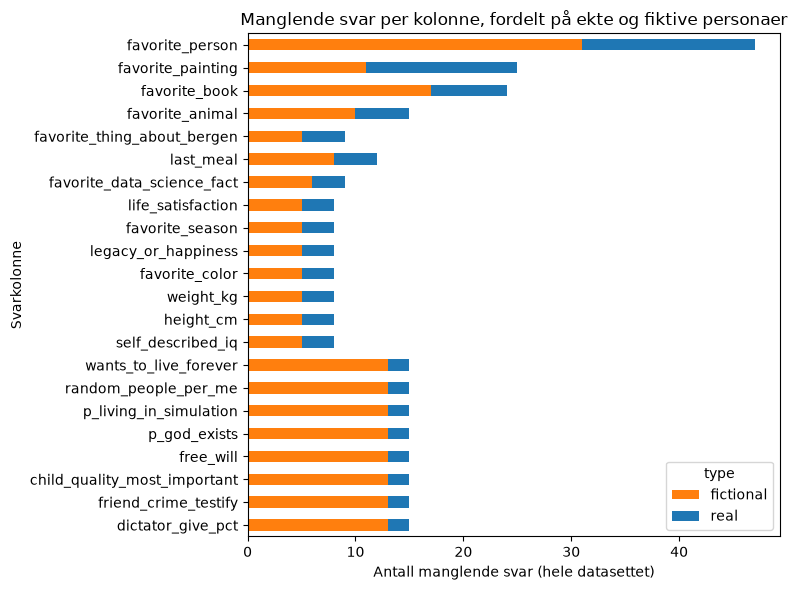

In [11]:
# Missing survey answers per column, split by type
miss_survey = df_full[survey_cols].isna().groupby(df_full["type"]).sum().T
miss_survey = miss_survey[miss_survey.sum(axis=1) > 0].sort_values("real")
miss_survey.index = miss_survey.index.str.replace("personal.", "").str.replace("values.", "")

fig, ax = plt.subplots(figsize=(8, 6))
miss_survey.plot.barh(stacked=True, ax=ax, color=["tab:orange", "tab:blue"])
ax.set_xlabel("Antall manglende svar (hele datasettet)")
ax.set_ylabel("Svarkolonne")
ax.set_title("Manglende svar per kolonne, fordelt på ekte og fiktive personaer")
ax.legend(title="type")
plt.tight_layout()
plt.savefig("img/manglende_data.png", dpi=200, bbox_inches="tight")
plt.show()

**Tolkning av manglende data:**

- **Svarene** mangler nesten bare seksjonsvis. Når språkmodellen ikke ga et gyldig
  svar på en hel seksjon (`values` for 15 personaer, de faste `personal`-spørsmålene
  for 8), mangler alle kolonnene i den seksjonen. `sections_ok` bekrefter dette.
  I tillegg mangler noen enkelte fritekstsvar (opp til 47 for `favorite_person`).
- **Big Five, politisk kompass og vekslingskurser mangler aldri.**
- **Fiktive personaer er sterkt overrepresentert** blant de manglende svarene,
  selv om de bare er 10 % av datasettet. Det mangler altså *ikke* helt tilfeldig
  (ikke MCAR). Trolig nekter eller klarer ikke språkmodellen alltid å svare som
  enkelte figurer. Det er en grunn til å behandle «mangler» som en egen kategori
  for kategoriske svar: at modellen ikke svarte, kan i seg selv være informativt.
- **Fasitkolonnene:** `born` mangler for 35 fiktive figurer (de mangler den sjette
  seksjonen med selvrapporterte fakta). `died` mangler for 2230. Det er forventet,
  siden den er tom for alle som lever, er udødelige eller aldersløse. `died` brukes
  uansett ikke som input.

Andelen manglende svar er under 0,5 % i alle kolonner. Det gir en enkel strategi i
modelleringen (seksjon 8): median-imputering for tall, en egen kategori for
kategorier og tom tekst for fritekst.

## 2. Trenings-, validerings- og testsplitt

Vi deler datasettet **før** resten av analysen, slik at valgene vi tar i del 1 og
del 2 (variabelutvalg, modellvalg, hyperparametre) ikke påvirkes av data vi senere
skal evaluere modellene på.

Vi bruker en 70/15/15-splitt og stratifiserer på `occupation_category`, som er
målvariabelen i klassifikasjonsoppgaven og ganske ubalansert (fra 373 til 3542
rader per klasse). Stratifisering sikrer at alle tre settene har tilnærmet lik
fordeling av yrkeskategorier. Manglende verdier i `occupation_category` behandles
som en egen gruppe i stratifiseringen, siden `train_test_split` ikke tillater NaN.

Resten av den utforskende analysen gjøres **kun på treningssettet**. Validerings- og
testsettet brukes først i del 2.

In [ ]:
# Stratification key: same as occupation_category, but with missing
# values treated as a separate group, since train_test_split does not allow NaN in stratify
strat_key = df_full["occupation_category"].fillna("missing")

# First split: 70% training, 30% used for validation + test
df_train, df_temp = train_test_split(df_full, test_size=0.30, stratify=strat_key, random_state=RANDOM_STATE)

# Second split: divide the remaining 30% equally into validation and test (15%/15% of the total)
df_val, df_test = train_test_split(df_temp, test_size=0.50, stratify=strat_key.loc[df_temp.index], random_state=RANDOM_STATE)

print("Trening:   ", df_train.shape)
print("Validering:", df_val.shape)
print("Test:      ", df_test.shape)

# Check that the class proportions and the real/fictional split are preserved
split_check = pd.DataFrame({name: d["occupation_category"].value_counts(normalize=True) for name, d in [("trening", df_train), ("validering", df_val), ("test", df_test)]})
split_check.loc["andel fiktive"] = [d["type"].eq("fictional").mean() for d in [df_train, df_val, df_test]]

# From this point onward, all exploratory analysis is performed on the training set
df = df_train.reset_index(drop=True)
split_check.round(3)

Trening:    (7000, 74)
Validering: (1500, 74)
Test:       (1500, 74)


,trening,validering,test
occupation_category,,,
politics & rule,0.356,0.355,0.355
performing arts,0.141,0.140,0.141
science & medicine,0.120,0.120,0.120
writing,0.087,0.088,0.087
philosophy & scholarship,0.065,0.065,0.065
other,0.064,0.064,0.064
visual arts & design,0.050,0.050,0.050
military,0.041,0.041,0.041
sport,0.039,0.039,0.039


Fordelingen av yrkeskategorier er nesten lik i de tre settene, og andelen fiktive
personaer (ca. 10 %) bevares også, selv om vi ikke stratifiserer på `type`.

## 3. Statistisk beskrivelse av alle variablene

Vi beskriver alle de 62 svarkolonnene og fasitkolonnene på treningssettet, gruppert
etter variabeltype.

### 3.1 Numeriske svar

In [13]:
numeric_survey = big_five_cols + plain_numeric + log_cols
numeric_desc = df[numeric_survey].describe().T
numeric_desc["mangler"] = df[numeric_survey].isna().sum()
numeric_desc["skjevhet"] = df[numeric_survey].skew()
numeric_desc.round(2)

,count,mean,std,min,25%,50%,75%,max,mangler,skjevhet
big_five.EXT1,7000.0,3.25,1.280000e+00,1.00,2.0,3.0,4.0,5.000000e+00,0,-0.14
big_five.EXT2,7000.0,2.89,1.300000e+00,1.00,2.0,3.0,4.0,5.000000e+00,0,-0.03
big_five.EXT5,7000.0,3.34,1.250000e+00,1.00,2.0,4.0,4.0,5.000000e+00,0,-0.10
big_five.EXT10,7000.0,3.25,1.160000e+00,1.00,2.0,3.0,4.0,5.000000e+00,0,0.03
big_five.EST1,7000.0,2.56,8.400000e-01,1.00,2.0,2.0,3.0,5.000000e+00,0,0.83
big_five.EST2,7000.0,3.72,8.800000e-01,1.00,4.0,4.0,4.0,5.000000e+00,0,-1.19
big_five.EST3,7000.0,2.92,1.040000e+00,1.00,2.0,3.0,4.0,5.000000e+00,0,0.41
big_five.EST10,7000.0,2.22,8.900000e-01,1.00,2.0,2.0,2.0,5.000000e+00,0,1.11
big_five.AGR1,7000.0,1.45,9.800000e-01,1.00,1.0,1.0,1.0,5.000000e+00,0,2.33
big_five.AGR2,7000.0,4.29,9.600000e-01,1.00,4.0,5.0,5.0,5.000000e+00,0,-1.38


- **Big Five** bruker hele skalaen 1–5, men mange ledd er svært skjeve. For eksempel
  har `AGR1` («I feel little concern for others») median 1, og `OPN9` («I spend time
  reflecting on things») median 5. Språkmodellen beskriver kjente personer som
  omtenksomme, reflekterte og planmessige.
- **`p_god_exists`** er spredt over hele 0–100, med median 75.
  **`p_living_in_simulation`** er nesten alltid 0. Det er ekstremt høyreskjevt.
- **`self_described_iq`** har median 145. Kjente personer tror altså de er langt over
  snittet på 100.
- **Vekslingskursene** og `random_people_per_me` har skjevhet fra ca. 3 til over 30.
  Medianen er moderat, men noen svar er $10^9$. Det er grunnen til at vi bruker
  $\log_{10}$ i modelleringen.

### 3.2 Kategoriske svar

Politisk kompass er en ordnet kategori (fire nivåer), så den beskrives her sammen
med de andre kategoriske svarene.

In [ ]:
category_rows = []
for col in political_cols + categorical_cols:
    counts = df[col].value_counts()
    category_rows.append({
        "kolonne": col, "mangler": df[col].isna().sum(), "antall kategorier": df[col].nunique(),
        "vanligste": counts.index[0], "andel vanligste (%)": round(100 * counts.iloc[0] / counts.sum(), 1),
        "sjeldneste": counts.index[-1], "andel sjeldneste (%)": round(100 * counts.iloc[-1] / counts.sum(), 1),
    })
pd.DataFrame(category_rows)

,kolonne,mangler,antall kategorier,vanligste,andel vanligste (%),sjeldneste,andel sjeldneste (%)
0,political_compass.econ_redistribute_wealth,0,4,disagree,44.9,strongly disagree,5.3
1,political_compass.econ_public_services,0,4,strongly agree,46.8,strongly disagree,1.4
2,political_compass.econ_tax_the_wealthy,0,4,agree,36.8,strongly disagree,6.1
3,political_compass.econ_free_markets,0,4,disagree,50.0,strongly agree,5.7
4,political_compass.econ_personal_responsibility,0,4,agree,45.5,strongly disagree,2.7
5,political_compass.econ_welfare_dependency,0,4,disagree,38.3,strongly disagree,10.2
6,political_compass.soc_immigration_benefits,0,4,agree,50.8,strongly disagree,2.7
7,political_compass.soc_legalize_drugs,0,4,strongly disagree,43.1,strongly agree,2.1
8,political_compass.soc_embrace_changing_norms,0,4,strongly disagree,29.1,agree,16.9
9,political_compass.soc_strong_leader,0,4,strongly agree,37.0,strongly disagree,3.3


Flere kategoriske svar er svært ubalanserte: 93 % velger *a lasting legacy* foran
*a happy life*, gull er favorittfargen til 40 %, og høst er favorittårstiden til to
av tre. Det sier mer om språkmodellen enn om personene. Den ser ut til å ha et fast
bilde av hvordan en «kjent person» svarer.

### 3.3 Fritekstsvar

In [15]:
text_rows = []
for col in text_columns:
    answers = df[col].dropna()
    text_rows.append({
        "kolonne": col, "mangler": df[col].isna().sum(), "unike svar": answers.nunique(),
        "snitt antall ord": round(answers.str.split().str.len().mean(), 1),
        "vanligste svar": answers.value_counts().index[0],
        "antall vanligste": answers.value_counts().iloc[0],
    })
pd.DataFrame(text_rows)

,kolonne,mangler,unike svar,snitt antall ord,vanligste svar,antall vanligste
0,personal.favorite_person,35,2557,2.1,Marcus Aurelius,165
1,personal.favorite_book,20,1486,3.4,The Art of War,505
2,personal.favorite_painting,18,900,3.8,The Starry Night,1329
3,personal.favorite_animal,11,554,1.2,Falcon,1303
4,personal.last_meal,7,2982,5.2,Coq au vin,180
5,personal.favorite_thing_about_bergen,6,4687,8.0,The mist over the fjords,146
6,personal.favorite_data_science_fact,5,6128,12.6,The ability to find patterns in the chaos of h...,37


Fritekstsvarene er av to slag. Korte «oppslagssvar» (`favorite_animal`,
`favorite_person`, `favorite_painting`) har få unike svar som går igjen. Det
vanligste dyret er falken, den vanligste boka *The Art of War*, og *The Starry Night*
og Marcus Aurelius dukker opp for svært mange. De åpne setningssvarene (`favorite_thing_about_bergen`,
`favorite_data_science_fact`) er nesten alltid unike. Der får språkmodellen mest rom
til å spille rollen.

### 3.4 Fasitkolonner og målvariabler

Fasitkolonnene brukes ikke som input i del 2, men de er viktige å forstå, spesielt
de to målvariablene `born` og `occupation_category`.

In [16]:
print(df[["born", "died", "fame_rank"]].describe().round(0).T)
print("\nKjønn:")
print(df["gender"].value_counts(dropna=False))
print("\nYrkeskategori:")
print(df["occupation_category"].value_counts(dropna=False))

            count    mean     std      min     25%     50%     75%      max
born       6976.0  1438.0   993.0 -10000.0  1434.0  1858.0  1927.0  10190.0
died       5415.0  1497.0   792.0  -3255.0  1397.0  1872.0  1970.0   2025.0
fame_rank  7000.0  4079.0  2734.0      1.0  1484.0  3982.0  6476.0   9000.0

Kjønn:
gender
M      5878
F      1098
NaN      24
Name: count, dtype: int64

Yrkeskategori:
occupation_category
politics & rule             2480
performing arts              980
science & medicine           837
writing                      608
philosophy & scholarship     453
other                        446
visual arts & design         350
military                     288
sport                        272
famous by association        261
NaN                           25
Name: count, dtype: int64


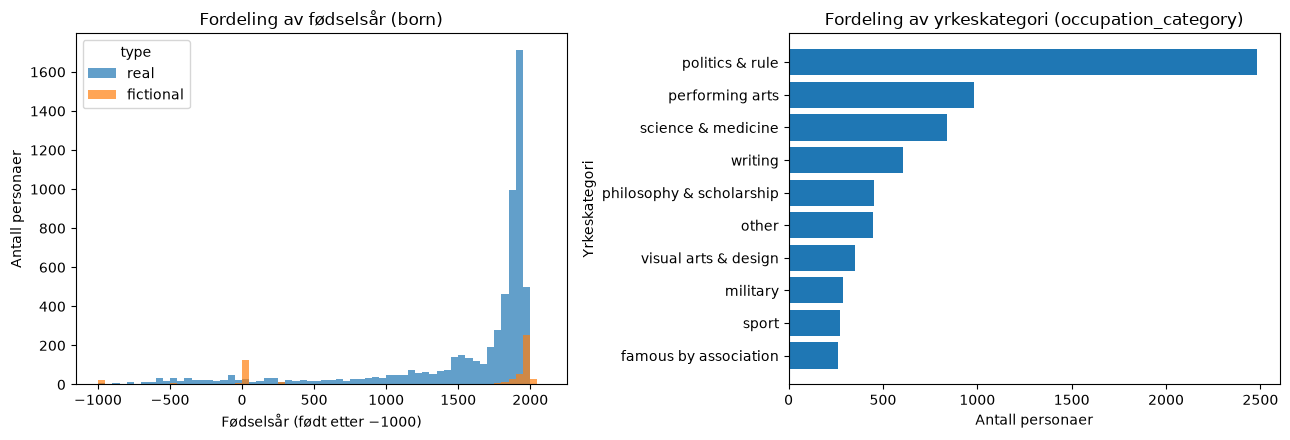

Andel født før −1000: 2.09 %
Andel født etter 2025: 0.26 %
Fødselsår for fiktive (median, min, maks): [1917.5, -10000.0, 10190.0]


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Birth year: only years after -1000 so the few extreme values don't squeeze the plot
bins = np.arange(-1000, 2101, 50)
for t, color in [("real", "tab:blue"), ("fictional", "tab:orange")]:
    years = df.loc[(df["type"] == t) & df["born"].between(-1000, 2100), "born"]
    axes[0].hist(years, bins=bins, alpha=0.7, color=color, label=t)
axes[0].set_xlabel("Fødselsår (født etter −1000)")
axes[0].set_ylabel("Antall personaer")
axes[0].set_title("Fordeling av fødselsår (born)")
axes[0].legend(title="type")

# Occupation category: number of personas per class
occ = df["occupation_category"].value_counts().sort_values()
axes[1].barh(occ.index, occ.values)
axes[1].set_xlabel("Antall personaer")
axes[1].set_ylabel("Yrkeskategori")
axes[1].set_title("Fordeling av yrkeskategori (occupation_category)")

plt.tight_layout()
plt.savefig("img/maalvariabler.png", dpi=200, bbox_inches="tight")
plt.show()

print("Andel født før −1000:", round((df["born"] < -1000).mean() * 100, 2), "%")
print("Andel født etter 2025:", round((df["born"] > 2025).mean() * 100, 2), "%")
print("Fødselsår for fiktive (median, min, maks):", df.loc[df["type"] == "fictional", "born"].agg(["median", "min", "max"]).tolist())

- **`born`** er sterkt venstreskjev: de fleste er født etter 1800, men halen strekker
  seg tilbake til antikken. I tillegg finnes noen ekstreme verdier helt ned til
  −10 000 og opp til 10 190, for det meste fiktive figurer (medianen for fiktive
  er likevel 1917). Det får betydning for valg
  av ytelsesmål (MAE framfor RMSE) i oppgave A.
- **`occupation_category`** er svært ubalansert. `politics & rule` er nesten ti ganger
  så stor som den minste klassen. Det får betydning for valg av ytelsesmål
  (balanced accuracy) og for `class_weight="balanced"` i oppgave B.

## 4. Fordelinger og sammenhenger

### 4.1 Skårene fra Big Five og det politiske kompasset

Vi regner ut de fem trekkskårene og de to politiske aksene slik datakatalogen
beskriver (seksjon 0.3), og ser på fordelingene deres.

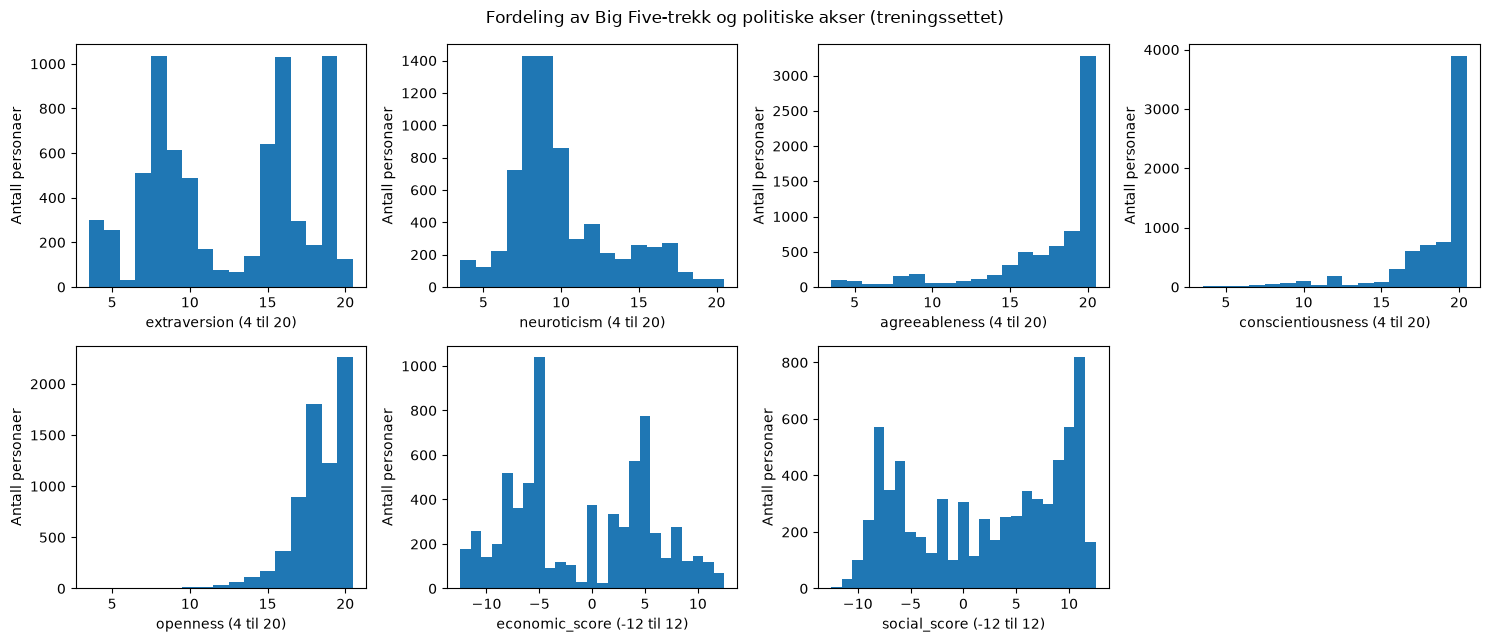

,count,mean,std,min,25%,50%,75%,max
extraversion,7000.0,12.45,4.84,4.0,8.0,13.0,16.0,20.0
neuroticism,7000.0,9.97,3.31,4.0,8.0,9.0,11.0,20.0
agreeableness,7000.0,17.40,3.89,4.0,16.0,19.0,20.0,20.0
conscientiousness,7000.0,18.33,2.89,4.0,18.0,20.0,20.0,20.0
openness,7000.0,18.30,1.82,4.0,18.0,18.0,20.0,20.0
economic_score,7000.0,-0.97,6.46,-12.0,-6.0,-1.0,5.0,12.0
social_score,7000.0,2.09,7.19,-12.0,-6.0,3.0,9.0,12.0


In [18]:
def score_survey(X):
    """Compute the Big Five trait scores and the two political compass axes.

    Parameters
    ----------
    X : DataFrame
        Raw survey answers.

    Returns
    -------
    DataFrame
        Five trait scores (4-20) and the economic and social axis (-12 to 12).
        Economic: positive = right. Social: positive = authoritarian.
    """
    pol = X[political_cols].apply(lambda col: col.map(score_map))
    b5 = X[big_five_cols].copy()
    b5[reversed_items] = 6 - b5[reversed_items]
    scores = pd.DataFrame({trait: b5[items].mean(axis=1) * 4 for trait, items in big_five_traits.items()})
    scores["economic_score"] = pol[economic_right].sum(axis=1) - pol[economic_left].sum(axis=1)
    scores["social_score"] = pol[social_authoritarian].sum(axis=1) - pol[social_libertarian].sum(axis=1)
    return scores


scores = score_survey(df)
df = pd.concat([df, scores], axis=1)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.flat, scores.columns):
    low, high = (4, 20) if col in big_five_traits else (-12, 12)
    ax.hist(df[col], bins=np.arange(low - 0.5, high + 1.5, 1))
    ax.set_xlabel(f"{col} ({low} til {high})")
    ax.set_ylabel("Antall personaer")
axes.flat[-1].axis("off")
fig.suptitle("Fordeling av Big Five-trekk og politiske akser (treningssettet)")
plt.tight_layout()
plt.savefig("img/skaarer_fordeling.png", dpi=200, bbox_inches="tight")
plt.show()

scores.describe().round(2).T

Personlighetsskårene er sterkt skjeve: omgjengelighet, planmessighet og åpenhet
ligger nesten alltid nær toppen av skalaen, mens nevrotisisme er lav. Det passer med
at språkmodellen gir et idealisert bilde av kjente personer. Ekstroversjon er det
eneste trekket som er spredt over hele skalaen, så det skiller mest mellom personer.
Den økonomiske aksen er tydelig bimodal (venstre/høyre), mens den sosiale aksen er
mer spredt.

### 4.2 Korrelasjoner mellom de numeriske variablene

Vi ser på korrelasjonen mellom skårene og de numeriske svarene. Høyde, vekt og
vekslingskursene er utelatt, siden de ekstreme verdiene ville dominert
korrelasjonen.

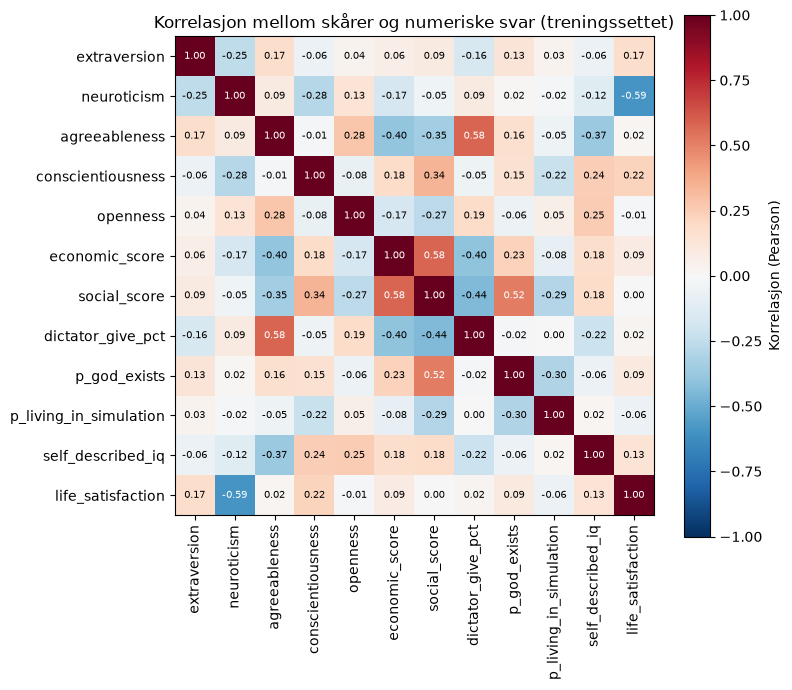

In [ ]:
corr_cols = list(scores.columns) + ["values.dictator_give_pct", "values.p_god_exists", "values.p_living_in_simulation", "personal.self_described_iq", "personal.life_satisfaction"]
short = [c.split(".")[-1] for c in corr_cols]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(short)), short, rotation=90)
ax.set_yticks(range(len(short)), short)
# Write the correlation in each cell
for i in range(len(short)):
    for j in range(len(short)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
        
fig.colorbar(im, ax=ax, label="Korrelasjon (Pearson)")
ax.set_title("Korrelasjon mellom skårer og numeriske svar (treningssettet)")
plt.tight_layout()
plt.savefig("img/korrelasjon.png", dpi=200, bbox_inches="tight")
plt.show()

- **Den økonomiske og den sosiale aksen** korrelerer (0,58), og den sosiale aksen
  henger sammen med tro på Gud (0,52). Språkmodellen plasserer altså personer langs
  én felles «konservativ–progressiv»-dimensjon mer enn i fire uavhengige kvadranter.
- **Omgjengelighet og `dictator_give_pct`** korrelerer (0,58): omgjengelige personaer
  gir mer til en fremmed. Omgjengelige er også mer liberale og venstreorienterte.
- **Nevrotisisme og livstilfredshet** korrelerer negativt (−0,59), slik vi ville
  forventet hos ekte mennesker.

Språkmodellens svar henger altså sammen på en måte som virker psykologisk
konsistent.

### 4.3 Hvilke svar henger sammen med når personen levde?

Dette er en forberedelse til oppgave A. Vi deler de ekte personene inn i fem epoker
etter fødselsår og sammenligner gjennomsnittet av noen svar. Fiktive figurer er
utelatt, siden fødselsårene deres er vilkårlige.

In [ ]:
# Real personas only, since fictional characters have arbitrary birth years
real = df[df["type"] == "real"].copy()
real["epoke"] = pd.cut(real["born"], bins=[-np.inf, 500, 1500, 1800, 1900, np.inf], labels=["før 500", "500–1500", "1500–1800", "1800–1900", "etter 1900"])

# Mean of some answers per era
era_cols = ["values.p_god_exists", "social_score", "economic_score",
            "values.p_living_in_simulation", "personal.self_described_iq"]
real.groupby("epoke", observed=True)[era_cols].mean().round(1)

,values.p_god_exists,social_score,economic_score,values.p_living_in_simulation,personal.self_described_iq
epoke,,,,,
før 500,78.5,5.3,0.1,3.0,147.8
500–1500,91.4,7.2,-0.2,1.6,142.8
1500–1800,85.6,5.6,1.7,0.9,143.3
1800–1900,59.6,1.6,-0.9,2.0,141.2
etter 1900,56.9,-1.6,-2.7,5.8,134.6


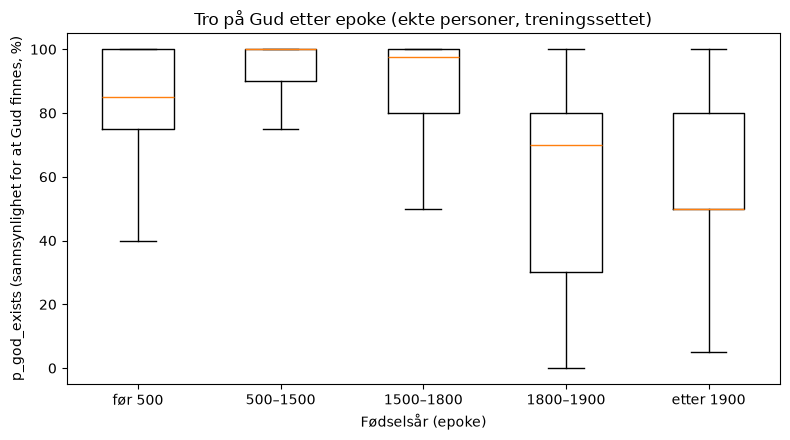

In [ ]:
# Belief in God by era
epochs = real["epoke"].cat.categories
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([real.loc[real["epoke"] == e, "values.p_god_exists"].dropna() for e in epochs], tick_labels=epochs, showfliers=False)
ax.set_xlabel("Fødselsår (epoke)")
ax.set_ylabel("p_god_exists (sannsynlighet for at Gud finnes, %)")
ax.set_title("Tro på Gud etter epoke (ekte personer, treningssettet)")
plt.tight_layout()
plt.savefig("img/gud_epoke.png", dpi=200, bbox_inches="tight")
plt.show()

Språkmodellen har et tydelig bilde av historien. Personer født 500–1800 tror i snitt
nesten sikkert at Gud finnes (86–91 %) og er mest autoritære, mens personer født
etter 1800 tror mindre på Gud (57–60 %) og er mer liberale. Moderne personer gir
også høyere sannsynlighet for at vi lever i en simulering, og lavere selvrapportert
IQ. Antikken (før 500) tror mindre på Gud enn middelalderen, trolig fordi mange
antikke personer var polyteister eller filosofer. Sammenhengen er ikke lineær, men
ser ut som et trinn rundt 1800. Det tyder på at trebaserte modeller kan passe godt i
oppgave A.

### 4.4 Livstilfredshet etter yrkeskategori

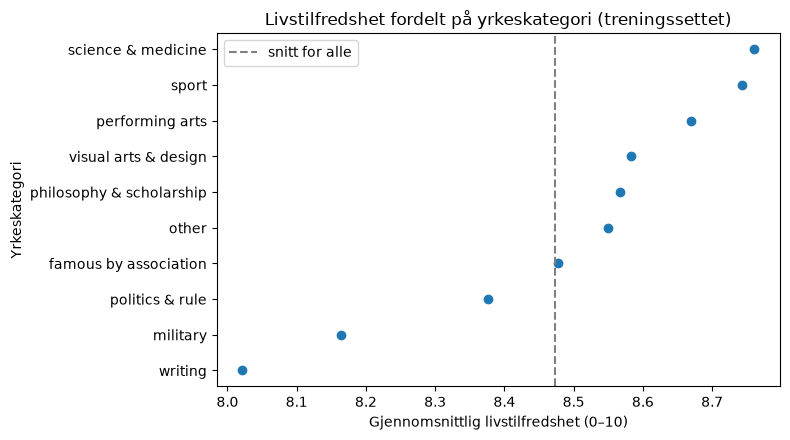

,median,mean
occupation_category,,
famous by association,9.0,8.48
military,8.0,8.16
other,9.0,8.55
performing arts,9.0,8.67
philosophy & scholarship,9.0,8.57
politics & rule,8.0,8.38
science & medicine,9.0,8.76
sport,9.0,8.74
visual arts & design,9.0,8.58


In [22]:
# Mean life satisfaction per occupation category, sorted
life = df.groupby("occupation_category")["personal.life_satisfaction"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(life.values, life.index, "o")
ax.axvline(df["personal.life_satisfaction"].mean(), color="grey", linestyle="--", label="snitt for alle")
ax.set_xlabel("Gjennomsnittlig livstilfredshet (0–10)")
ax.set_ylabel("Yrkeskategori")
ax.set_title("Livstilfredshet fordelt på yrkeskategori (treningssettet)")
ax.legend()
plt.tight_layout()
plt.savefig("img/livstilfredshet.png", dpi=200, bbox_inches="tight")
plt.show()

df.groupby("occupation_category")["personal.life_satisfaction"].agg(["median", "mean"]).round(2)

Livstilfredsheten er høy for alle yrkeskategorier (median 8–9), og forskjellene er
små: `writing` og `military` ligger lavest, mens `science & medicine` og `sport` ligger
høyest. Språkmodellen ser ut til å ha et bilde av den plagede forfatteren. Likevel
er livstilfredshet alene et svakt signal for yrke.

### 4.5 Politisk orientering etter yrkeskategori

Hver yrkeskategori plasseres i det politiske kompasset med gjennomsnittet av de to
aksene.

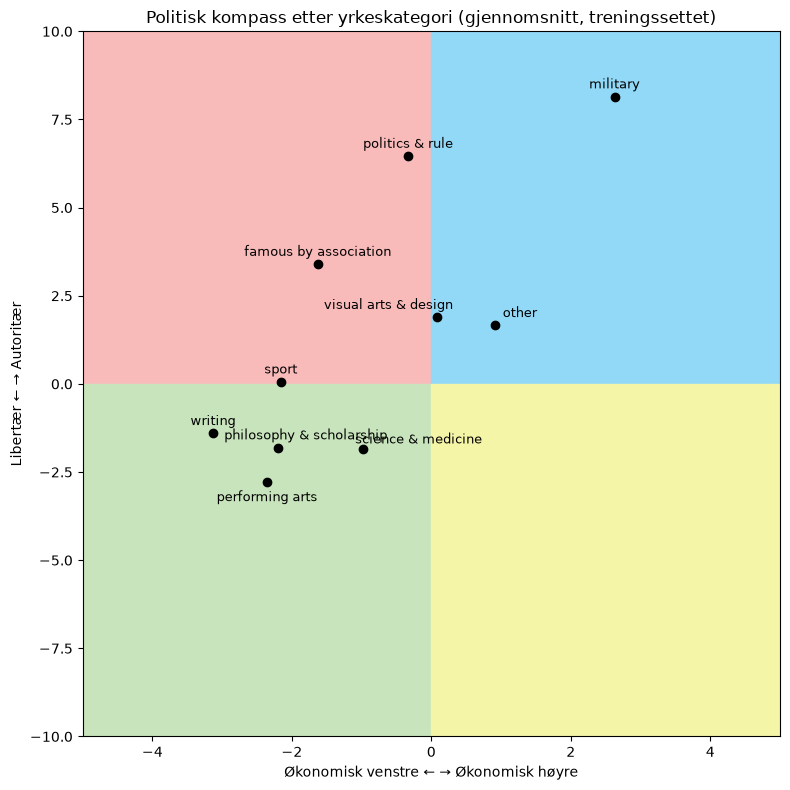

,economic_score,social_score
occupation_category,,
famous by association,-1.63,3.39
military,2.63,8.15
other,0.91,1.66
performing arts,-2.36,-2.77
philosophy & scholarship,-2.20,-1.81
politics & rule,-0.33,6.46
science & medicine,-0.98,-1.85
sport,-2.16,0.06
visual arts & design,0.08,1.89


In [ ]:
political_by_occupation = df.groupby("occupation_category")[["economic_score", "social_score"]].mean()

fig, ax = plt.subplots(figsize=(8, 8))
# The four quadrants of the political compass
ax.fill_between([-5, 0], 0, 10, color="#f9baba")    # authoritarian left
ax.fill_between([0, 5], 0, 10, color="#92d9f8")     # authoritarian right
ax.fill_between([-5, 0], -10, 0, color="#c8e4bc")   # libertarian left
ax.fill_between([0, 5], -10, 0, color="#f5f5a7")    # libertarian right
ax.scatter(political_by_occupation["economic_score"], political_by_occupation["social_score"], color="black")
# Labels that would overlap are placed below or to the side of the point
offsets = {"philosophy & scholarship": (20, 6), "performing arts": (0, -14), "science & medicine": (40, 4), "other": (18, 6), "visual arts & design": (-35, 6)}
for name, row in political_by_occupation.iterrows():
    ax.annotate(name, (row["economic_score"], row["social_score"]), textcoords="offset points", xytext=offsets.get(name, (0, 6)), ha="center", fontsize=9)
ax.set_xlim(-5, 5)
ax.set_ylim(-10, 10)
ax.set_xlabel("Økonomisk venstre ← → Økonomisk høyre")
ax.set_ylabel("Libertær ← → Autoritær")
ax.set_title("Politisk kompass etter yrkeskategori (gjennomsnitt, treningssettet)")
plt.tight_layout()
plt.savefig("img/political_compass_occupation.png", dpi=200, bbox_inches="tight")
plt.show()

political_by_occupation.round(2)

`politics & rule` og `military` skiller seg ut på den autoritære siden, og `military`
også på den økonomiske høyresiden. `writing`, `philosophy & scholarship`, `science &
medicine` og `performing arts` ligger på den liberale venstresiden, mens `visual arts &
design` overraskende nok ligger nær midten, litt mot den autoritære siden. Språkmodellen
knytter altså ulike politiske profiler til ulike yrker. Det tyder på at svarene bærer
informasjon om yrke, noe vi utnytter i oppgave B.

## 5. Gruppeforskjeller mellom ekte og fiktive personaer

### 5.1 Tror fiktive personaer i større grad at de lever i en simulering?

Vi sammenligner `values.p_living_in_simulation` for ekte og fiktive personaer med
et boxplot og Welch's t-test (ulike varianser og ulik gruppestørrelse).

**H₀:** Fiktive personaer har ikke høyere gjennomsnittlig svar enn ekte personaer.

**H₁:** Fiktive personaer har høyere gjennomsnittlig svar enn ekte personaer.

Vi bruker et signifikansnivå på 5 %.

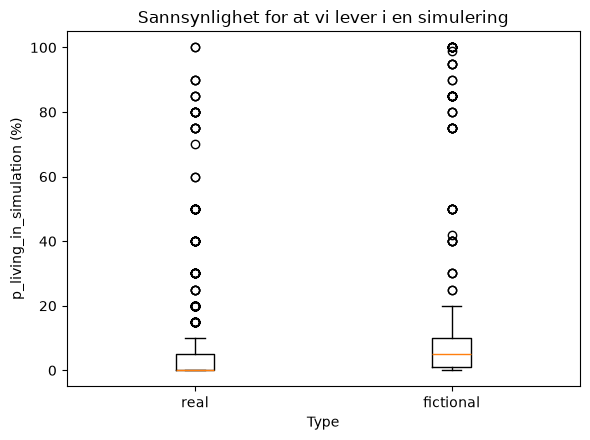

           count   mean  median    std
type                                  
fictional    691  11.35     5.0  20.61
real        6299   3.20     0.0   6.86

t-statistikk: 10.319
p-verdi: 1.19e-23
Vi forkaster H0.


In [24]:
real_sim = df.loc[df["type"] == "real", "values.p_living_in_simulation"].dropna()
fictional_sim = df.loc[df["type"] == "fictional", "values.p_living_in_simulation"].dropna()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot([real_sim, fictional_sim], tick_labels=["real", "fictional"])
ax.set_xlabel("Type")
ax.set_ylabel("p_living_in_simulation (%)")
ax.set_title("Sannsynlighet for at vi lever i en simulering")
plt.tight_layout()
plt.savefig("img/simulation_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

# One-sided Welch's t-test: H1 is mean(fictional) > mean(real)
t_stat, p_value = ttest_ind(fictional_sim, real_sim, equal_var=False, alternative="greater")
print(df.groupby("type")["values.p_living_in_simulation"].agg(["count", "mean", "median", "std"]).round(2))
print(f"\nt-statistikk: {t_stat:.3f}")
print(f"p-verdi: {p_value:.3g}")
print("Vi forkaster H0." if p_value < 0.05 else "Vi kan ikke forkaste H0.")

Fiktive personaer har klart høyere gjennomsnitt, og p-verdien er langt under 0,05,
så vi forkaster H₀. Fordelingen er svært skjev (de fleste svarer 0), men med flere
hundre observasjoner i hver gruppe er t-testen likevel rimelig på grunn av
sentralgrenseteoremet.

## 6. Systematiske mønstre i tekstsvar

Vi undersøker om tekstsvarene skiller ekte og fiktive personaer. Til dette bruker vi
TF-IDF og logistisk regresjon. Målet er ikke den beste modellen, men å finne hvilke
spørsmål og ord som skiller gruppene. Vi velger logistisk regresjon fordi
koeffisientene er direkte tolkbare.

### 6.1 Hvilke tekstvariabler skiller gruppene?

Vi trener én modell per tekstvariabel og bruker stratifisert 10-fold kryssvalidering
på treningssettet, med balanced accuracy som mål (9:1-ubalanse mellom gruppene).
Vi tar med de tre korte kategoriske svarene (farge, årstid, legacy) i tillegg til de
sju fritekstene.

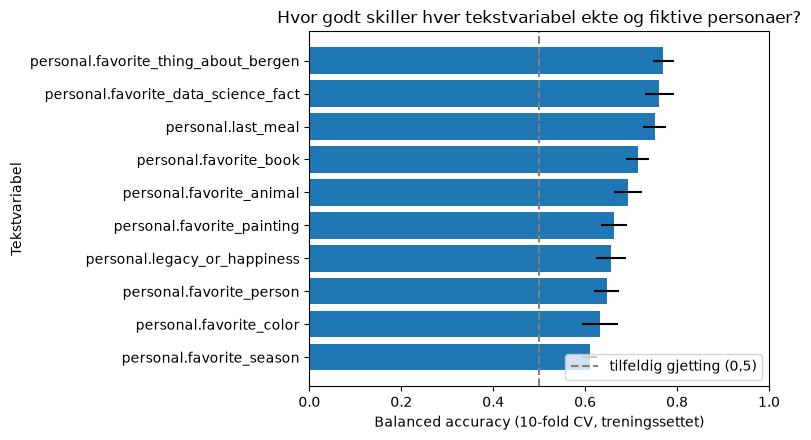

,variabel,balanced_accuracy,std
5,personal.favorite_thing_about_bergen,0.770,0.023
6,personal.favorite_data_science_fact,0.761,0.032
4,personal.last_meal,0.752,0.025
1,personal.favorite_book,0.714,0.026
3,personal.favorite_animal,0.694,0.031
2,personal.favorite_painting,0.663,0.028
9,personal.legacy_or_happiness,0.656,0.032
0,personal.favorite_person,0.647,0.027
7,personal.favorite_color,0.632,0.039
8,personal.favorite_season,0.610,0.017


In [ ]:
eda_text_columns = text_columns + ["personal.favorite_color", "personal.favorite_season", "personal.legacy_or_happiness"]
y_type = df["type"]
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

results = []
for column in eda_text_columns:
    # TF-IDF of the single text variable, then logistic regression
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english")),
        ("logreg", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
    ])
    scores_cv = cross_val_score(pipe, df[column].fillna(""), y_type, cv=cv, scoring="balanced_accuracy")
    results.append({"variabel": column, "balanced_accuracy": scores_cv.mean(), "std": scores_cv.std()})

variable_results = pd.DataFrame(results).sort_values("balanced_accuracy")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(variable_results["variabel"], variable_results["balanced_accuracy"], xerr=variable_results["std"])
ax.axvline(0.5, color="grey", linestyle="--", label="tilfeldig gjetting (0,5)")
ax.set_xlim(0, 1)
ax.set_xlabel("Balanced accuracy (10-fold CV, treningssettet)")
ax.set_ylabel("Tekstvariabel")
ax.set_title("Hvor godt skiller hver tekstvariabel ekte og fiktive personaer?")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("img/tekstvariabler_type.png", dpi=200, bbox_inches="tight")
plt.show()

variable_results.sort_values("balanced_accuracy", ascending=False).round(3)

### 6.2 Hvilke ord skiller gruppene?

Vi trener én modell på alle tekstsvarene samlet og ser på koeffisientene. Positive
koeffisienter trekker mot `fictional`, negative mot `real`.

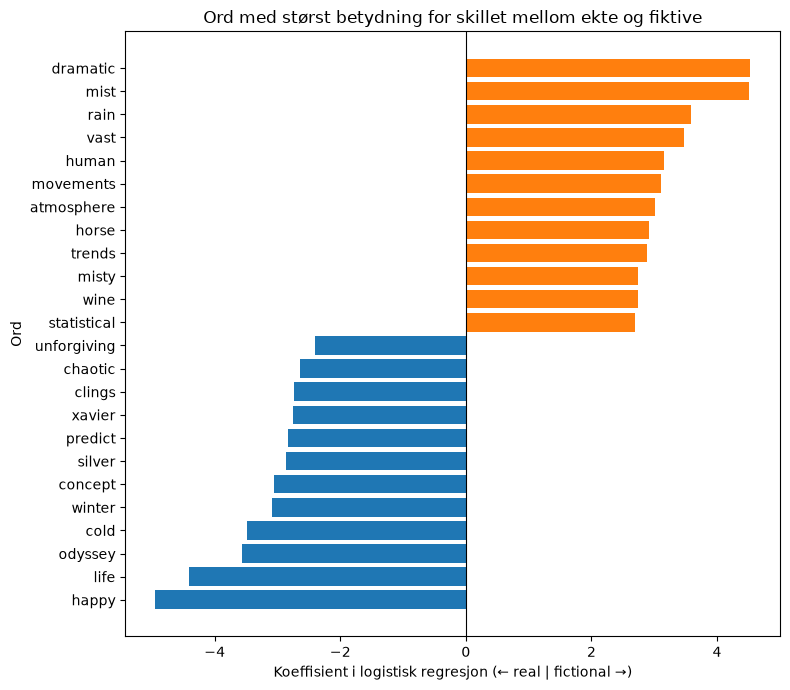

In [26]:
combined_text = df[eda_text_columns].fillna("").astype(str).agg(" ".join, axis=1)

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
pipeline.fit(combined_text, y_type)

coef_df = pd.DataFrame({
    "ord": pipeline.named_steps["tfidf"].get_feature_names_out(),
    "koeffisient": pipeline.named_steps["logreg"].coef_[0],   # positive = fictional
}).sort_values("koeffisient")
top_words = pd.concat([coef_df.head(12), coef_df.tail(12)])

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_words["ord"], top_words["koeffisient"],
        color=np.where(top_words["koeffisient"] > 0, "tab:orange", "tab:blue"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Koeffisient i logistisk regresjon (← real | fictional →)")
ax.set_ylabel("Ord")
ax.set_title("Ord med størst betydning for skillet mellom ekte og fiktive")
plt.tight_layout()
plt.savefig("img/real_fictional_words.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Oppsummering av del 1

- **Datakvalitet:** ingen duplikater, ingen ugyldige verdier, og under 0,5 % manglende
  svar per kolonne. Manglende svar kommer seksjonsvis og er overrepresentert blant
  fiktive personaer. Ekstreme, men gyldige verdier beholdes.
- **Språkmodellens «kjente person»:** høy omgjengelighet, planmessighet og åpenhet,
  IQ rundt 145, gull som favorittfarge og en varig ettermæle framfor et lykkelig liv.
- **Historie:** tro på Gud, autoritære holdninger og selvrapportert IQ faller for
  personer født etter ca. 1800, mens troen på at vi lever i en simulering øker. Det motiverer oppgave A og ikke-lineære modeller.
- **Yrke:** det politiske kompasset skiller tydelig mellom yrkeskategorier
  (militære autoritære og høyre, akademikere, forfattere og utøvende kunstnere
  liberale og venstre).
- **Ekte mot fiktiv:** fiktive tror mer på at vi lever i en simulering (Welch's
  t-test), og fritekstene skiller gruppene godt.

Alt dette tolkes som mønstre i hvordan språkmodellen representerer personene, ikke
som egenskaper ved personene selv.

# Del 2 – Prediktiv modellering

Del 2 inneholder to oppgaver:

- **Oppgave A – Regresjon:** predikere fødselsåret `born` (seksjon 10).
- **Oppgave B – Klassifikasjon:** predikere `occupation_category` (seksjon 11).

Begge oppgavene bruker **kun** de 62 svarene språkmodellen ga i spørreundersøkelsen
som input. Fasitkolonner som `occupation`, `name`, `died`, `type` osv. brukes ikke som
input. `type` brukes bare i etterkant til å analysere feilene.

Vi bruker splitten fra seksjon 2. Alle modeller tilpasses på treningssettet, alle
valg (modelltype, hyperparametre og variabelsett) gjøres på valideringssettet, og
testsettet brukes **én gang** per oppgave på den valgte modellen. Seksjon 8–9 er
felles for begge oppgavene.

## 8. Variabelutvinning og manglende data

### 8.1 Variabelutvinning (feature engineering)

Vi lager mer meningsfulle variabler ut fra svarene:

| variabel | hvordan | hvorfor |
|---|---|---|
| 5 Big Five-skårer | reverserte ledd snus med `6 − x`, snittet av leddene × 4 (4–20) | datakatalogens skåring. Snitt × 4 gjør at et manglende ledd ikke trekker skåren ned |
| 2 politiske akser | −2, −1, +1, +2, summert per akse (−12 til +12) | datakatalogens skåring |
| 9 log-variabler | $\log_{10}$ av vekslingskursene og `random_people_per_me` | spenner fra $10^{-12}$ til $10^9$ (klippes nedad ved $10^{-6}$) |
| 7 ordtellinger | antall ord i hvert fritekstsvar | lengden på svaret kan si noe om rollen (del 1, seksjon 3.3) |
| `n_missing` | antall manglende svar for personaen | manglende svar er ikke tilfeldige (del 1, seksjon 1.4) |
| `all_text` | alle sju fritekstsvar slått sammen | én TF-IDF-modell for all tekst |
| 32 enkeltledd | Big Five-leddene (snudd) og de politiske utsagnene som tall | valgfritt. Vi tester på valideringssettet om de gir noe ekstra utover skårene |

Alt dette skjer i funksjonen `add_features`, som legges **inn i pipelinen** via
`FunctionTransformer`. Den jobber rad for rad og lærer ingenting fra dataene, så
den kan ikke lekke informasjon fra validerings- eller testsettet.

### 8.2 Strategi for manglende data

| variabeltype | strategi | begrunnelse |
|---|---|---|
| numerisk | median fra treningsdata | robust mot de skjeve fordelingene. Gjelder under 0,5 % av radene |
| kategorisk | egen kategori `"missing"` | at språkmodellen ikke svarte, er informativt (overrepresentert blant fiktive) |
| fritekst | tom tekst | gir ingen ord til TF-IDF, i stedet for å finne på et svar |
| Big Five | snitt av de besvarte leddene × 4 | mangler aldri i dataene, men gjør pipelinen robust for nye data |
| politiske utsagn | 0 (nøytral) | skalaen hopper over 0, så 0 trekker ikke aksen i noen retning. Mangler aldri i dataene |
| målvariabelen | raden fjernes i den oppgaven | vi kan verken trene eller evaluere uten fasit |

Medianen læres inne i pipelinen (`SimpleImputer`), og bare fra dataene modellen
trenes på.

In [27]:
# Number-of-words features, one per free-text answer
word_count_cols = [f"n_words_{col.split('.')[-1]}" for col in text_columns]

# Numerical input variables used by the models
numeric_cols = (list(big_five_traits) + ["economic_score", "social_score"] + plain_numeric  + [f"log_{col}" for col in log_cols] + word_count_cols + ["n_missing"])

# Optional: the single Big Five items and political statements as numbers
item_cols = big_five_cols + political_cols


def add_features(X):
    """Create engineered features from the raw survey answers.

    Works row by row and learns nothing from the data, so it can be used
    inside a pipeline without leaking information from validation/test.

    Parameters
    ----------
    X : DataFrame
        The raw survey columns.

    Returns
    -------
    DataFrame
        A copy of X with Big Five scores, political compass axes,
        log-transformed values, word counts, number of missing answers,
        cleaned categories and combined text added.
    """
    X = X.copy()

    # How many answers are missing for this persona (before anything is filled in)
    X["n_missing"] = X[survey_cols].isna().sum(axis=1)

    # Political compass: text answers to numbers. Positive = right / authoritarian
    for col in political_cols:
        X[col] = X[col].map(score_map)
    X["economic_score"] = X[economic_right].sum(axis=1) - X[economic_left].sum(axis=1)
    X["social_score"] = X[social_authoritarian].sum(axis=1) - X[social_libertarian].sum(axis=1)

    # Big Five: reverse the (R) items, then mean of the answered items times 4 (4-20)
    X[reversed_items] = 6 - X[reversed_items]
    for trait, items in big_five_traits.items():
        X[trait] = X[items].mean(axis=1) * 4

    # log10 of values spanning many orders of magnitude (clip to avoid log(0))
    for col in log_cols:
        X[f"log_{col}"] = np.log10(pd.to_numeric(X[col], errors="coerce").clip(lower=1e-6))

    # Categorical answers: missing values become their own category
    for col in categorical_cols:
        X[col] = X[col].astype(object).where(X[col].notna(), "missing").astype(str)

    # Free text: missing answers become empty text, then word counts and one combined text
    for col, count_col in zip(text_columns, word_count_cols):
        X[col] = X[col].fillna("").astype(str)
        X[count_col] = X[col].str.split().str.len()
    X["all_text"] = X[text_columns].agg(" ".join, axis=1)

    return X


# Quick check of the engineered numerical features on the training set
add_features(df_train[survey_cols])[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
extraversion,7000.0,12.45,4.84,4.0,8.0,13.0,16.0,20.0
neuroticism,7000.0,9.97,3.31,4.0,8.0,9.0,11.0,20.0
agreeableness,7000.0,17.40,3.89,4.0,16.0,19.0,20.0,20.0
conscientiousness,7000.0,18.33,2.89,4.0,18.0,20.0,20.0,20.0
openness,7000.0,18.30,1.82,4.0,18.0,18.0,20.0,20.0
economic_score,7000.0,-0.97,6.46,-12.0,-6.0,-1.0,5.0,12.0
social_score,7000.0,2.09,7.19,-12.0,-6.0,3.0,9.0,12.0
values.dictator_give_pct,6990.0,43.05,24.52,0.0,50.0,50.0,50.0,100.0
values.p_god_exists,6990.0,67.70,31.77,0.0,50.0,75.0,100.0,100.0
values.p_living_in_simulation,6990.0,4.01,9.50,0.0,0.0,0.0,5.0,100.0


## 9. Felles modelloppsett

Én funksjon bygger en pipeline ut fra hvilke variabelgrupper vi vil bruke. Den brukes
både til regresjon og klassifikasjon, slik at all forbehandling skjer inne i
pipelinen og bare lærer fra treningsdataene.

| gruppe | forbehandling |
|---|---|
| numerisk (+ evt. enkeltledd) | median-imputering → `StandardScaler` |
| kategorisk | `OneHotEncoder` |
| tekst | `TfidfVectorizer` (engelske stoppord fjernet, ord som finnes i minst 2 svar) |

Med `max_words` beholder TF-IDF bare de vanligste ordene. Det bruker vi for Random
Forest: et tre som skal velge mellom flere tusen glisne ordkolonner, blir tregt og
finner sjelden de nyttige ordene. Med få ord gjør vi matrisen tett, som er mye raskere
for Random Forest.

In [28]:
def make_model(estimator, numeric=False, categorical=False, text=None, items=False, max_words=None):
    """Build a pipeline: feature engineering -> preprocessing -> model.

    Parameters
    ----------
    estimator : sklearn estimator
        The model placed at the end of the pipeline.
    numeric : bool
        Include the numerical features (median imputation + standardization).
    categorical : bool
        Include the categorical features (one-hot encoding).
    text : str or None
        Name of a text column to use with TF-IDF, e.g. a single free-text
        column or "all_text". None means no text.
    items : bool
        Also include the single Big Five items and political statements.
    max_words : int or None
        Keep only this many words in TF-IDF (the most frequent ones).
        The output matrix is then dense, which is faster for Random Forest.

    Returns
    -------
    Pipeline
        An unfitted pipeline that takes the raw survey columns as input.
    """
    transformers = []

    # Numerical features: fill missing values with the median, then standardize
    if numeric:
        cols = numeric_cols + (item_cols if items else [])
        transformers.append(("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), cols))

    # Categorical features: one column per category
    if categorical:
        transformers.append(("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols))

    # Free text: TF-IDF on words that appear in at least two answers
    if text is not None:
        transformers.append(("text", TfidfVectorizer(stop_words="english", min_df=2, max_features=max_words), text))

    # With a limited vocabulary the matrix is small, so we make it dense
    sparse_threshold = 0 if max_words is not None else 0.3

    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("prep", ColumnTransformer(transformers, sparse_threshold=sparse_threshold)),
        ("model", estimator),
    ])


def cv_check(models, X, y, scoring, cv):
    """Cross-validate a few candidate models on the training set only.

    Used as a robustness check of the validation results, not to pick the model.

    Parameters
    ----------
    models : dict
        Model name -> pipeline. Each is cloned (refitted from scratch) in every fold.
    X, y : DataFrame, Series
        Training data.
    scoring : str
        sklearn scoring name.
    cv : cross-validation splitter

    Returns
    -------
    DataFrame
        Mean and standard deviation of the score over the folds, per model.
    """
    rows = []
    for name, model in models.items():
        s = cross_val_score(model, X, y, cv=cv, scoring=scoring)
        rows.append({"model": name, "CV-snitt": s.mean(), "CV-std": s.std()})
    return pd.DataFrame(rows)

## 10. Oppgave A – Regresjon: når levde personen?

Vi predikerer fødselsåret `born` ut fra svarene.

**Ytelsesmål: MAE (mean absolute error) i år.** MAE er lett å tolke («modellen bommer i
snitt med X år»). Fødselsårene spenner fra −10 000 til 10 190 (seksjon 3.4). RMSE
ville latt noen få fiktive figurer med vilkårlige år dominere hele målet, så vi
foretrekker MAE. I tillegg rapporterer vi **medianfeil**, som er enda mer robust.

Rader der `born` mangler fjernes.

In [29]:
TARGET_A = "born"

# Remove rows where the birth year is missing
train_a = df_train.dropna(subset=[TARGET_A])
val_a = df_val.dropna(subset=[TARGET_A])
test_a = df_test.dropna(subset=[TARGET_A])

# Input: only the survey answers. Target: birth year
Xa_train, ya_train = train_a[survey_cols], train_a[TARGET_A]
Xa_val, ya_val = val_a[survey_cols], val_a[TARGET_A]
Xa_test, ya_test = test_a[survey_cols], test_a[TARGET_A]

print("Trening:   ", Xa_train.shape)
print("Validering:", Xa_val.shape)
print("Test:      ", Xa_test.shape)

Trening:    (6976, 62)
Validering: (1495, 62)
Test:       (1494, 62)


### 10.1 Modeller

- **Baseline:** prediker alltid medianen av fødselsår i treningssettet.
- **Lineær regresjon** på numerisk + kategorisk, som en enkel lineær referanse.
- **Lineær modell tilpasset med gradient descent** (`SGDRegressor`). Vi velger
  tapsfunksjonen selv: med `loss="epsilon_insensitive"` og `epsilon=0` er tapet
  $|y - \hat{y}|$, altså **det samme som MAE**. Vanlig lineær regresjon minimerer
  kvadratfeil og blir dratt mot de ekstreme fødselsårene, mens absoluttfeil er robust
  mot dem. Modellen oppdateres med små steg mot den negative gradienten, ett
  datapunkt om gangen (stokastisk gradient descent). Med en L2-straff
  $\alpha \sum \beta_j^2$ tåler den også tusenvis av TF-IDF-ord. Vi tuner $\alpha$
  (0,0001, 0,001, 0,01). Fødselsåret standardiseres under treningen
  (`TransformedTargetRegressor`), slik at stegene får en fornuftig størrelse.
- **Random Forest** på numerisk + kategorisk. Den kan fange ikke-lineære
  sammenhenger, som trinnet rundt 1800 i del 1 (seksjon 4.3). Vi tuner `max_depth`
  (10, 20, ubegrenset) og `min_samples_leaf` (1, 3, 10), som styrer hvor komplekse
  trærne blir.

**Variabelutvalg** gjøres på gruppenivå. For Random Forest sammenligner vi på
valideringssettet om det hjelper å legge til (1) enkeltleddene og (2) tekst (de 300
eller 1000 vanligste ordene).

In [30]:
results_a = []      # one row per evaluated model
candidates_a = {}   # name -> model, used to pick the final model

def evaluate_reg(name, model):
    """Fit a regression model on the training set and evaluate it on the validation set.

    Computes MAE and median absolute error (in years), prints them, and stores
    the result in results_a and the model in candidates_a.

    Parameters
    ----------
    name : str
        Name of the model, used in the results table.
    model : Pipeline
        The model to fit and evaluate.
    """
    model.fit(Xa_train, ya_train)
    pred = model.predict(Xa_val)
    row = {"model": name, "MAE": mean_absolute_error(ya_val, pred), "medianfeil": median_absolute_error(ya_val, pred)}
    results_a.append(row)
    candidates_a[name] = model
    print(f"{name:45s} MAE = {row['MAE']:6.1f} år   medianfeil = {row['medianfeil']:6.1f} år")


def sgd_reg(alpha):
    """Linear model fitted with stochastic gradient descent on the absolute error.

    epsilon_insensitive loss with epsilon=0 is |y - prediction|, the same as MAE.
    The target is standardized during training so the gradient steps get a sensible size.
    """
    sgd = SGDRegressor(loss="epsilon_insensitive", epsilon=0, alpha=alpha, max_iter=2000, random_state=RANDOM_STATE)
    return TransformedTargetRegressor(regressor=sgd, transformer=StandardScaler())


def rf_reg(depth, leaf):
    """Random Forest regressor with the given max_depth and min_samples_leaf."""
    return RandomForestRegressor(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, n_jobs=-1, random_state=RANDOM_STATE)


# Baseline and linear models
evaluate_reg("Baseline (median)", Pipeline([("model", DummyRegressor(strategy="median"))]))
evaluate_reg("LinReg: num + kat", make_model(LinearRegression(), numeric=True, categorical=True))
evaluate_reg("SGD (abs. feil): num + kat", make_model(sgd_reg(0.001), numeric=True, categorical=True))
for alpha in [0.0001, 0.001, 0.01]:
    evaluate_reg(f"SGD (abs. feil): alle svar (alpha={alpha})", make_model(sgd_reg(alpha), numeric=True, categorical=True, text="all_text"))

Baseline (median)                             MAE =  504.1 år   medianfeil =   90.0 år
LinReg: num + kat                             MAE =  508.8 år   medianfeil =  303.5 år
SGD (abs. feil): num + kat                    MAE =  438.2 år   medianfeil =  128.4 år
SGD (abs. feil): alle svar (alpha=0.0001)     MAE =  357.7 år   medianfeil =  108.8 år
SGD (abs. feil): alle svar (alpha=0.001)      MAE =  358.2 år   medianfeil =  105.7 år
SGD (abs. feil): alle svar (alpha=0.01)       MAE =  382.7 år   medianfeil =  106.0 år


In [31]:
# Random Forest: tune max_depth and min_samples_leaf on the validation set
for depth in [10, 20, None]:
    for leaf in [1, 3, 10]:
        evaluate_reg(f"RF: num + kat (depth={depth}, leaf={leaf})",
                     make_model(rf_reg(depth, leaf), numeric=True, categorical=True))

RF: num + kat (depth=10, leaf=1)              MAE =  398.7 år   medianfeil =  158.8 år
RF: num + kat (depth=10, leaf=3)              MAE =  393.1 år   medianfeil =  154.3 år
RF: num + kat (depth=10, leaf=10)             MAE =  396.4 år   medianfeil =  160.9 år
RF: num + kat (depth=20, leaf=1)              MAE =  378.5 år   medianfeil =  147.6 år
RF: num + kat (depth=20, leaf=3)              MAE =  373.2 år   medianfeil =  148.6 år
RF: num + kat (depth=20, leaf=10)             MAE =  385.0 år   medianfeil =  158.0 år
RF: num + kat (depth=None, leaf=1)            MAE =  377.9 år   medianfeil =  152.0 år
RF: num + kat (depth=None, leaf=3)            MAE =  372.9 år   medianfeil =  147.7 år
RF: num + kat (depth=None, leaf=10)           MAE =  384.8 år   medianfeil =  157.5 år


In [32]:
# Best Random Forest hyperparameters from the grid above
rf_rows = pd.DataFrame(results_a)
rf_rows = rf_rows[rf_rows["model"].str.startswith("RF: num + kat (")]
best_rf = rf_rows.loc[rf_rows["MAE"].idxmin(), "model"]
best_depth = candidates_a[best_rf].named_steps["model"].max_depth
best_leaf = candidates_a[best_rf].named_steps["model"].min_samples_leaf
print("Beste Random Forest:", best_rf)

# Variable selection: does adding the single items or the text help?
evaluate_reg("RF: num + kat + ledd", make_model(rf_reg(best_depth, best_leaf), numeric=True, categorical=True, items=True))

for n_words in [300, 1000]:
    evaluate_reg(f"RF: alle svar ({n_words} ord)", make_model(rf_reg(best_depth, best_leaf), numeric=True, categorical=True, text="all_text", max_words=n_words))

Beste Random Forest: RF: num + kat (depth=None, leaf=3)
RF: num + kat + ledd                          MAE =  370.9 år   medianfeil =  147.2 år
RF: alle svar (300 ord)                       MAE =  304.1 år   medianfeil =  109.2 år
RF: alle svar (1000 ord)                      MAE =  308.6 år   medianfeil =  100.3 år


### 10.2 Sammenligning på valideringssettet

,model,MAE,medianfeil
0,RF: alle svar (300 ord),304.1,109.2
1,RF: alle svar (1000 ord),308.6,100.3
2,SGD (abs. feil): alle svar (alpha=0.0001),357.7,108.8
3,SGD (abs. feil): alle svar (alpha=0.001),358.2,105.7
4,RF: num + kat + ledd,370.9,147.2
5,"RF: num + kat (depth=None, leaf=3)",372.9,147.7
6,"RF: num + kat (depth=20, leaf=3)",373.2,148.6
7,"RF: num + kat (depth=None, leaf=1)",377.9,152.0
8,"RF: num + kat (depth=20, leaf=1)",378.5,147.6
9,SGD (abs. feil): alle svar (alpha=0.01),382.7,106.0


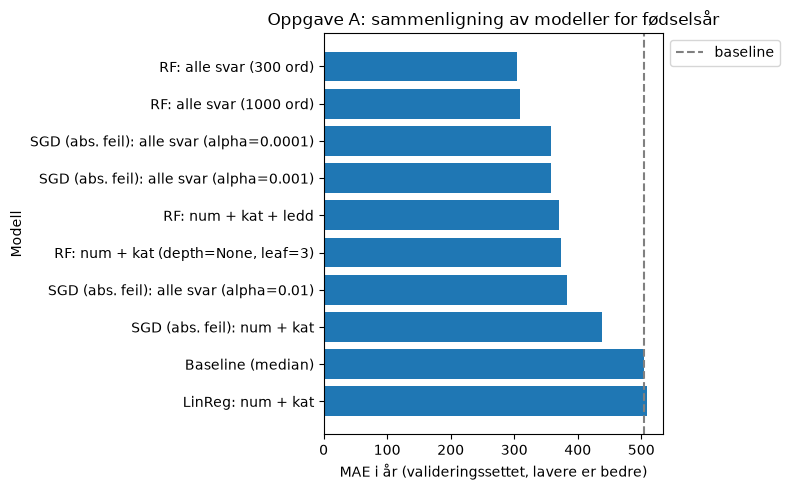

In [33]:
results_a_df = pd.DataFrame(results_a).sort_values("MAE").reset_index(drop=True)
display(results_a_df.round(1))

# Bar chart of validation MAE for all models (Random Forest grid: only the best one)
plot_a = results_a_df[~results_a_df["model"].str.startswith("RF: num + kat (") | (results_a_df["model"] == best_rf)]
plot_a = plot_a.sort_values("MAE", ascending=False)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(plot_a) + 1))
ax.barh(plot_a["model"], plot_a["MAE"])
ax.axvline(plot_a.loc[plot_a["model"] == "Baseline (median)", "MAE"].iloc[0], color="grey", linestyle="--", label="baseline")
ax.set_xlabel("MAE i år (valideringssettet, lavere er bedre)")
ax.set_ylabel("Modell")
ax.set_title("Oppgave A: sammenligning av modeller for fødselsår")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig("img/modellsammenligning_born.png", dpi=200, bbox_inches="tight")
plt.show()

**Kort oppsummering (validering):**

- **Lineær regresjon uten tekst er ikke bedre enn baseline** (509 mot 504 år).
  Sammenhengen mellom svarene og fødselsår er ikke lineær (jf. trinnet rundt 1800 i
  seksjon 4.3).
- **Gradient descent med absoluttfeil hjelper mye.** Den samme lineære modellen
  tilpasset med SGD på absoluttfeil får 438 år uten tekst og 358 år med tekst.
  Absoluttfeil lar seg ikke dra av de ekstreme fødselsårene, slik kvadratfeil gjør.
  `alpha=0.0001` og `0.001` er nesten like, mens `0.01` regulariserer for mye.
- **Random Forest:** `max_depth=10` er for grunt (undertilpasning). Fra dybde 20 er
  resultatene nesten like, og `min_samples_leaf=3` er best.
- **Variabelutvalg:** tekst gir den største forbedringen (373 → 304 år for Random
  Forest). 300 ord er litt bedre enn 1000. Enkeltleddene gir nesten ingenting utover
  de summerte skårene.
- **Ingen modell slår baseline på medianfeil** (90 år). Medianen 1858 treffer den store
  gruppen moderne personer godt, mens modellene bytter litt større feil på dem mot
  mye mindre feil på eldre personer.

### 10.3 Robusthetssjekk med kryssvalidering

Ett valideringssett på ca. 1500 personer gir usikre tall (i del 2 falt resultatet i
oppgave B fra validering til test). Som en sjekk kjører vi 5-fold kryssvalidering
**på treningssettet** for de tre beste modellene. Det brukes ikke til å velge
modell, men til å se om rekkefølgen og forskjellene er stabile.

In [ ]:
top3_a = results_a_df["model"].head(3).tolist()
cv_a = cv_check({name: candidates_a[name] for name in top3_a}, Xa_train, ya_train, scoring="neg_mean_absolute_error", cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))

# sklearn uses negative MAE (higher is better), so we flip the sign back
cv_a["CV-snitt"] = -cv_a["CV-snitt"]
cv_a.merge(results_a_df[["model", "MAE"]], on="model").rename(columns={
    "CV-snitt": "MAE (5-fold CV)", "CV-std": "std over fold", "MAE": "MAE (validering)"}).round(1)

,model,MAE (5-fold CV),std over fold,MAE (validering)
0,RF: alle svar (300 ord),316.3,12.6,304.1
1,RF: alle svar (1000 ord),312.0,15.0,308.6
2,SGD (abs. feil): alle svar (alpha=0.0001),348.4,17.6,357.7


Kryssvalideringen bekrefter at Random Forest med tekst er best, ca. 30–35 år bedre
enn SGD, som er omtrent to standardavvik over foldene. Forskjellen mellom 300 og 1000
ord er derimot bare 3–5 år og bytter fortegn mellom validering og CV, altså støy. Vi
følger regelen og velger etter valideringssettet: **Random Forest på alle svar med de
300 vanligste ordene**.

### 10.4 Hvilke svar bruker modellen? (permutasjonsviktighet)

Før vi trener den valgte modellen på nytt, måler vi hvor viktig hvert av de 62
svarene er. Vi stokker én svarkolonne om gangen i **valideringssettet** og ser hvor
mye MAE øker. Siden pipelinen tar rådata som input, måler vi viktigheten av hvert
spørsmål, ikke av hver avledede variabel. Når en fritekstkolonne stokkes, påvirker det
både `all_text` og ordtellingen.

Valgt modell: RF: alle svar (300 ord)


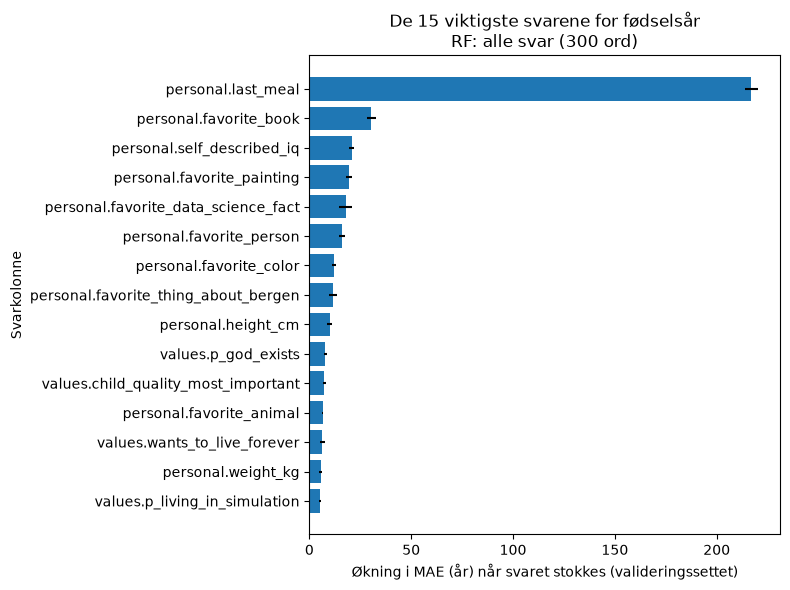

,svar,økning i MAE,std
52,personal.last_meal,217.0,3.1
46,personal.favorite_book,30.5,2.2
41,personal.self_described_iq,20.7,1.2
44,personal.favorite_painting,19.4,1.4
49,personal.favorite_data_science_fact,17.8,3.1
40,personal.favorite_person,15.9,1.4
45,personal.favorite_color,12.2,0.9
48,personal.favorite_thing_about_bergen,11.6,1.9
42,personal.height_cm,10.0,1.2
36,values.p_god_exists,7.9,0.5


In [35]:
# Pick the model with the lowest validation MAE
best_name_a = results_a_df.iloc[0]["model"]
print("Valgt modell:", best_name_a)

# Permutation importance on the validation set, with the model fitted on the training set only
perm = permutation_importance(candidates_a[best_name_a], Xa_val, ya_val, scoring="neg_mean_absolute_error", n_repeats=5, random_state=RANDOM_STATE)
importance_a = pd.DataFrame({"svar": survey_cols, "økning i MAE": perm.importances_mean, "std": perm.importances_std}).sort_values("økning i MAE")
top_imp = importance_a.tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_imp["svar"], top_imp["økning i MAE"], xerr=top_imp["std"])
ax.set_xlabel("Økning i MAE (år) når svaret stokkes (valideringssettet)")
ax.set_ylabel("Svarkolonne")
ax.set_title(f"De 15 viktigste svarene for fødselsår\n{best_name_a}")
plt.tight_layout()
plt.savefig("img/viktighet_born.png", dpi=200, bbox_inches="tight")
plt.show()

importance_a.tail(10).iloc[::-1].round(1)

**`last_meal` er klart det viktigste svaret** for å anslå når en person levde: å
stokke det øker MAE med over 200 år. Språkmodellen lar historiske personer velge mat
fra sin egen tid og kultur. Deretter kommer favorittbok, selvrapportert IQ,
favorittmaleri og data science-svaret. Personlighet og politikk betyr lite når teksten
er med.

### 10.5 Endelig modell og evaluering på testsettet

Den valgte modellen trenes på nytt på trening + validering (mer data), og evalueres
**én gang** på testsettet.

In [ ]:
# Retrain on training + validation, then evaluate once on the test set
final_model_a = candidates_a[best_name_a]
final_model_a.fit(pd.concat([Xa_train, Xa_val]), pd.concat([ya_train, ya_val]))
pred_a = final_model_a.predict(Xa_test)

test_mae_a = mean_absolute_error(ya_test, pred_a)
test_median_a = median_absolute_error(ya_test, pred_a)
print(f"Test MAE:        {test_mae_a:.1f} år")
print(f"Test medianfeil: {test_median_a:.1f} år")

# For comparison: the baseline refitted on training + validation
baseline_a = DummyRegressor(strategy="median").fit(pd.concat([Xa_train, Xa_val]), pd.concat([ya_train, ya_val]))
print(f"Baseline på test: MAE = {mean_absolute_error(ya_test, baseline_a.predict(Xa_test)):.1f} år, "
      f"medianfeil = {median_absolute_error(ya_test, baseline_a.predict(Xa_test)):.1f} år")

# Error split by real vs fictional (type is used only for analysis, not as input)
errors_a = pd.DataFrame({"type": test_a["type"], "abs_feil": (ya_test - pred_a).abs()})
errors_a.groupby("type")["abs_feil"].agg(["count", "mean", "median"]).round(1)

Test MAE:        285.2 år
Test medianfeil: 94.2 år
Baseline på test: MAE = 452.2 år, medianfeil = 90.0 år


,count,mean,median
type,,,
fictional,156,929.0,579.4
real,1338,210.2,79.2


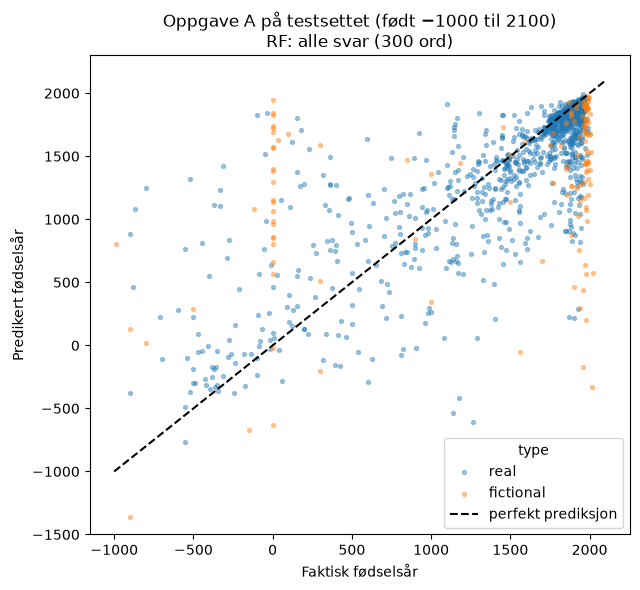

,count,mean,median
born,,,
før 500,139,650.0,416.0
500–1500,212,315.0,229.0
1500–1800,202,159.0,94.0
1800–1900,335,123.0,41.0
etter 1900,450,113.0,44.0


In [ ]:
# Only show birth years after -1000 so a few extreme values don't squeeze the plot
mask = (ya_test > -1000) & (ya_test < 2100)
lims = [-1000, 2100]

fig, ax = plt.subplots(figsize=(6.5, 6))
for t, color in [("real", "tab:blue"), ("fictional", "tab:orange")]:
    m = mask & (test_a["type"] == t)
    ax.scatter(ya_test[m], pred_a[m.values], s=8, alpha=0.4, color=color, label=t)
ax.plot(lims, lims, "k--", label="perfekt prediksjon")
ax.set_ylim(-1500, 2300)   # a few extreme predictions are outside the plot
ax.set_xlabel("Faktisk fødselsår")
ax.set_ylabel("Predikert fødselsår")
ax.set_title(f"Oppgave A på testsettet (født −1000 til 2100)\n{best_name_a}")
ax.legend(title="type")
plt.tight_layout()
plt.savefig("img/regresjon_pred_vs_faktisk.png", dpi=200, bbox_inches="tight")
plt.show()

# Error by historical era, real personas only
real_test = test_a["type"] == "real"
era_test = pd.cut(ya_test[real_test], bins=[-np.inf, 500, 1500, 1800, 1900, np.inf], labels=["før 500", "500–1500", "1500–1800", "1800–1900", "etter 1900"])
errors_a[real_test].groupby(era_test, observed=True)["abs_feil"].agg(["count", "mean", "median"]).round(0)

**Kort oppsummering (test):**

- Den valgte modellen får **MAE 285 år og medianfeil 94 år** på testsettet, mot 452 og
  90 år for baseline. Den er altså mye bedre på MAE, men ikke på medianfeil.
- Testresultatet er litt bedre enn på validering (304 år), innenfor variasjonen vi så
  i kryssvalideringen.
- **Fiktive figurer** har over fire ganger så stor gjennomsnittsfeil som ekte personer.
  Det vises som den loddrette stripen rundt år 0 i figuren, der mytologiske og bibelske
  figurer predikeres som moderne.
- **Feilen øker kraftig bakover i tid:** median 41–44 år for personer født etter 1800,
  men over 400 år for antikken. Prediksjonene presses mot midten (*regression to the
  mean*), siden det er få gamle personer å lære av.

## 11. Oppgave B – Klassifikasjon av `occupation_category`

Målet er å predikere hvilken av de 10 yrkeskategoriene en persona tilhører.

**Ytelsesmål: balanced accuracy.** Klassene er svært ubalanserte (seksjon 3.4). Vanlig
accuracy ville belønnet en modell som nesten bare gjetter `politics & rule`. Balanced
accuracy er gjennomsnittet av recall per klasse, så hver klasse teller like mye, og
tilfeldig gjetting gir ca. 0,10. Vi rapporterer også **makro-F1**, som i tillegg tar
hensyn til precision.

Alle modellene bruker `class_weight="balanced"`, som vekter sjeldne klasser opp under
treningen.

Rader der `occupation_category` mangler fjernes.

In [38]:
TARGET_B = "occupation_category"

# Remove rows where the occupation category is missing
train_b = df_train.dropna(subset=[TARGET_B])
val_b = df_val.dropna(subset=[TARGET_B])
test_b = df_test.dropna(subset=[TARGET_B])

# Input: only the survey answers. Target: occupation category
X_train, y_train = train_b[survey_cols], train_b[TARGET_B]
X_val, y_val = val_b[survey_cols], val_b[TARGET_B]
X_test, y_test = test_b[survey_cols], test_b[TARGET_B]

print("Trening:   ", X_train.shape)
print("Validering:", X_val.shape)
print("Test:      ", X_test.shape)

Trening:    (6975, 62)
Validering: (1495, 62)
Test:       (1494, 62)


In [39]:
results_b = []      # one row per evaluated model
candidates_b = {}   # name -> model, used to pick the final model

def logreg(C=1.0):
    """Logistic regression with balanced class weights. Smaller C gives a simpler model."""
    return LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE)


def sgd_clf(alpha):
    """Logistic regression fitted with stochastic gradient descent, with balanced class weights.

    Larger alpha gives stronger L2 regularization, i.e. a simpler model.
    """
    return SGDClassifier(loss="log_loss", alpha=alpha, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)


def evaluate(name, model):
    """Fit a classifier on the training set and evaluate it on the validation set.

    Computes balanced accuracy and macro-F1, prints them, and stores the
    result in results_b and the model in candidates_b.

    Parameters
    ----------
    name : str
        Name of the model, used in the results table.
    model : Pipeline
        The model to fit and evaluate.
    """
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    row = {"model": name, "balanced_accuracy": balanced_accuracy_score(y_val, pred), "makro_F1": f1_score(y_val, pred, average="macro")}
    results_b.append(row)
    candidates_b[name] = model
    print(f"{name:45s} bal.acc = {row['balanced_accuracy']:.3f}   makro-F1 = {row['makro_F1']:.3f}")

### 11.1 Modellsøk

Vi går fram trinn for trinn, fra enkle til mer komplekse modeller:

1. **Baseline:** gjetter alltid den største klassen.
2. **Spørreskjema uten tekst:** logistisk regresjon på numeriske og kategoriske svar,
   hver for seg og sammen, og med enkeltledd. I tillegg Random Forest, som kan fange
   ikke-lineære samspill.
3. **Tekst:** TF-IDF + logistisk regresjon på hver fritekstvariabel for seg (bare for å
   forstå hvor informasjonen ligger) og på all tekst samlet.
4. **Alle svar kombinert:** logistisk regresjon med tuning av `C`, med og uten
   enkeltledd.
5. **Gradient descent:** den samme logistiske modellen tilpasset med stokastisk
   gradient descent (`SGDClassifier` med `loss="log_loss"`). `LogisticRegression`
   bruker en annen optimeringsmetode (L-BFGS) som regner på hele datasettet i hvert
   steg, mens SGD tar mange små steg, ett datapunkt om gangen. Det er raskere på store
   data, men gir en mer støyete løsning. Vi tuner regulariseringen `alpha`.

In [40]:
# Step 1: baseline, always predict the largest class
evaluate("Baseline (største klasse)", Pipeline([("model", DummyClassifier(strategy="most_frequent"))]))

# Step 2: the survey without text
evaluate("LogReg: numerisk", make_model(logreg(), numeric=True))
evaluate("LogReg: kategorisk", make_model(logreg(), categorical=True))
evaluate("LogReg: num + kat", make_model(logreg(), numeric=True, categorical=True))
evaluate("LogReg: num + kat + ledd", make_model(logreg(), numeric=True, categorical=True, items=True))

rf_clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
evaluate("RF: num + kat + ledd", make_model(rf_clf, numeric=True, categorical=True, items=True))

Baseline (største klasse)                     bal.acc = 0.100   makro-F1 = 0.052
LogReg: numerisk                              bal.acc = 0.543   makro-F1 = 0.492
LogReg: kategorisk                            bal.acc = 0.426   makro-F1 = 0.355
LogReg: num + kat                             bal.acc = 0.598   makro-F1 = 0.538
LogReg: num + kat + ledd                      bal.acc = 0.649   makro-F1 = 0.596
RF: num + kat + ledd                          bal.acc = 0.646   makro-F1 = 0.602


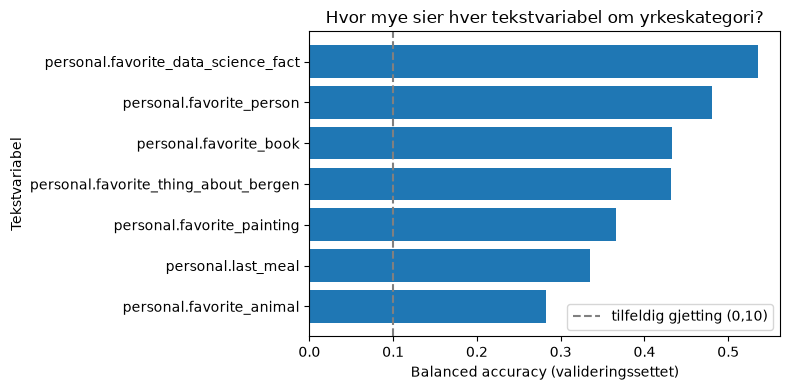

LogReg: all tekst                             bal.acc = 0.694   makro-F1 = 0.652


,variabel,balanced_accuracy
6,personal.favorite_data_science_fact,0.535
0,personal.favorite_person,0.480
1,personal.favorite_book,0.433
5,personal.favorite_thing_about_bergen,0.432
2,personal.favorite_painting,0.366
4,personal.last_meal,0.335
3,personal.favorite_animal,0.283


In [41]:
# Step 3a: one TF-IDF + logistic regression model per free-text variable
# Only to understand where the information is, not candidates for the final model
text_results = []
for col in text_columns:
    model = make_model(logreg(), text=col).fit(X_train, y_train)
    text_results.append({"variabel": col, "balanced_accuracy": balanced_accuracy_score(y_val, model.predict(X_val))})
text_results = pd.DataFrame(text_results).sort_values("balanced_accuracy")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(text_results["variabel"], text_results["balanced_accuracy"])
ax.axvline(0.10, color="grey", linestyle="--", label="tilfeldig gjetting (0,10)")
ax.set_xlabel("Balanced accuracy (valideringssettet)")
ax.set_ylabel("Tekstvariabel")
ax.set_title("Hvor mye sier hver tekstvariabel om yrkeskategori?")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("img/tekstvariabler_yrke.png", dpi=200, bbox_inches="tight")
plt.show()

# Step 3b: all free text combined
evaluate("LogReg: all tekst", make_model(logreg(), text="all_text"))
text_results.sort_values("balanced_accuracy", ascending=False).round(3)

In [42]:
# Step 4: all answers in one model, tuning the regularization strength C
for C in [0.1, 1, 10]:
    evaluate(f"LogReg: alle svar (C={C})", make_model(logreg(C), numeric=True, categorical=True, text="all_text"))

evaluate("LogReg: alle svar + ledd (C=1)", make_model(logreg(1), numeric=True, categorical=True, text="all_text", items=True))

LogReg: alle svar (C=0.1)                     bal.acc = 0.657   makro-F1 = 0.601
LogReg: alle svar (C=1)                       bal.acc = 0.743   makro-F1 = 0.703
LogReg: alle svar (C=10)                      bal.acc = 0.725   makro-F1 = 0.708
LogReg: alle svar + ledd (C=1)                bal.acc = 0.732   makro-F1 = 0.700


In [43]:
# Step 5: the same logistic model, fitted with stochastic gradient descent
for alpha in [0.00001, 0.0001, 0.001]:
    evaluate(f"SGD (log-tap): alle svar (alpha={alpha})",
             make_model(sgd_clf(alpha), numeric=True, categorical=True, text="all_text"))

SGD (log-tap): alle svar (alpha=1e-05)        bal.acc = 0.660   makro-F1 = 0.656
SGD (log-tap): alle svar (alpha=0.0001)       bal.acc = 0.710   makro-F1 = 0.687
SGD (log-tap): alle svar (alpha=0.001)        bal.acc = 0.630   makro-F1 = 0.614


### 11.2 Sammenligning på valideringssettet

,model,balanced_accuracy,makro_F1
0,LogReg: alle svar (C=1),0.743,0.703
1,LogReg: alle svar + ledd (C=1),0.732,0.700
2,LogReg: alle svar (C=10),0.725,0.708
3,SGD (log-tap): alle svar (alpha=0.0001),0.710,0.687
4,LogReg: all tekst,0.694,0.652
5,SGD (log-tap): alle svar (alpha=1e-05),0.660,0.656
6,LogReg: alle svar (C=0.1),0.657,0.601
7,LogReg: num + kat + ledd,0.649,0.596
8,RF: num + kat + ledd,0.646,0.602
9,SGD (log-tap): alle svar (alpha=0.001),0.630,0.614


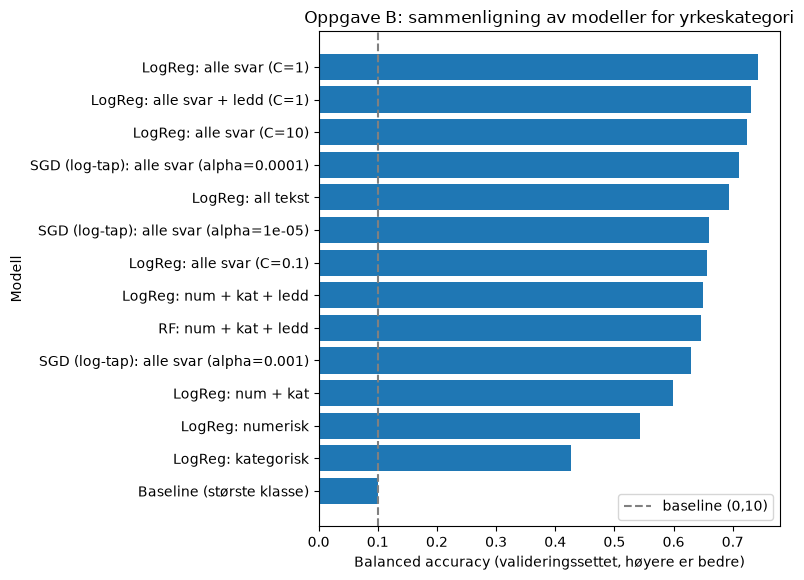

In [44]:
results_b_df = pd.DataFrame(results_b).sort_values("balanced_accuracy", ascending=False).reset_index(drop=True)
display(results_b_df.round(3))

plot_b = results_b_df.sort_values("balanced_accuracy")
fig, ax = plt.subplots(figsize=(8, 0.35 * len(plot_b) + 1))
ax.barh(plot_b["model"], plot_b["balanced_accuracy"])
ax.axvline(0.10, color="grey", linestyle="--", label="baseline (0,10)")
ax.set_xlabel("Balanced accuracy (valideringssettet, høyere er bedre)")
ax.set_ylabel("Modell")
ax.set_title("Oppgave B: sammenligning av modeller for yrkeskategori")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("img/modellsammenligning_yrke.png", dpi=200, bbox_inches="tight")
plt.show()

**Kort oppsummering (validering):**

- **Uten tekst** gir enkeltleddene en tydelig forbedring for logistisk regresjon
  (0,598 → 0,650). Random Forest er omtrent like god (0,646).
- **Tekst alene (0,694) er bedre enn alle de andre svarene til sammen**, og å kombinere
  alt gir best resultat (0,743).
- **Regularisering:** `C=0.1` gir for enkel modell, `C=1` er best, og `C=10` er litt
  dårligere.
- **Gradient descent (SGD)** gir 0,713 med best `alpha`, litt dårligere enn den samme
  modellen tilpasset med L-BFGS (0,743). SGD tar mange støyete steg og ender ikke helt
  i optimum, og den er følsom for valget av `alpha`: 0,00001 overtilpasser og 0,001
  undertilpasser.
- Med tekst hjelper ikke enkeltleddene lenger (0,731 mot 0,743).

### 11.3 Robusthetssjekk med kryssvalidering

Som i oppgave A kjører vi stratifisert 5-fold kryssvalidering på treningssettet for
de tre beste modellene, som en sjekk av om forskjellene er større enn støyen.

In [ ]:
top3_b = results_b_df["model"].head(3).tolist()
cv_b = cv_check({name: candidates_b[name] for name in top3_b}, X_train, y_train, scoring="balanced_accuracy", cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
cv_b.merge(results_b_df[["model", "balanced_accuracy"]], on="model").rename(columns={
    "CV-snitt": "bal.acc (5-fold CV)", "CV-std": "std over fold", "balanced_accuracy": "bal.acc (validering)"}).round(3)

,model,bal.acc (5-fold CV),std over fold,bal.acc (validering)
0,LogReg: alle svar (C=1),0.694,0.015,0.743
1,LogReg: alle svar + ledd (C=1),0.709,0.010,0.732
2,LogReg: alle svar (C=10),0.688,0.015,0.725


Her er kryssvalideringen nyttig. **Valideringsvinneren (LogReg, alle svar, C=1) er
ikke best i CV.** Modellen med enkeltledd får 0,710 mot 0,693, og valideringstallet
(0,743) ligger langt over CV-snittet. Det er et typisk eksempel på at vi velger
modellen som *tilfeldigvis* gjorde det best på ett valideringssett blant 14 kandidater
(*winner's curse*). Forskjellen er likevel bare omtrent ett standardavvik over foldene.

Vi følger den forhåndsbestemte regelen og velger på valideringssettet. Å bytte modell
etter å ha sett CV-tallene ville vært et nytt modellvalg uten et urørt valideringssett.

### 11.4 Endelig modell og evaluering på testsettet

Vi velger modellen med høyest balanced accuracy på valideringssettet, trener den på
nytt på trening + validering, og evaluerer **én gang** på testsettet.

In [46]:
best_name_b = results_b_df.iloc[0]["model"]
print("Valgt modell:", best_name_b)

# Retrain on training + validation, then evaluate once on the test set
final_model_b = candidates_b[best_name_b]
final_model_b.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
test_pred = final_model_b.predict(X_test)

test_bacc_b = balanced_accuracy_score(y_test, test_pred)
test_f1_b = f1_score(y_test, test_pred, average="macro")
print(f"\nTest balanced accuracy: {test_bacc_b:.3f}")
print(f"Test makro-F1:          {test_f1_b:.3f}")
print(f"Test accuracy:          {accuracy_score(y_test, test_pred):.3f}\n")

# Precision, recall and F1 for each class
print(classification_report(y_test, test_pred, digits=2))

Valgt modell: LogReg: alle svar (C=1)

Test balanced accuracy: 0.692
Test makro-F1:          0.662
Test accuracy:          0.735

                          precision    recall  f1-score   support

   famous by association       0.30      0.46      0.36        56
                military       0.55      0.74      0.63        62
                   other       0.49      0.54      0.51        95
         performing arts       0.81      0.81      0.81       210
philosophy & scholarship       0.61      0.71      0.66        97
         politics & rule       0.93      0.76      0.84       531
      science & medicine       0.88      0.85      0.87       179
                   sport       0.60      0.66      0.63        59
    visual arts & design       0.63      0.76      0.69        75
                 writing       0.62      0.62      0.62       130

                accuracy                           0.73      1494
               macro avg       0.64      0.69      0.66      1494
          

Test balanced accuracy er 0,692, nesten nøyaktig CV-snittet (0,693) og klart lavere
enn valideringstallet (0,743). CV ga altså et bedre anslag enn ett valideringssett.
`science & medicine`, `performing arts` og `politics & rule` er lettest, mens
sekkekategoriene `other` og `famous by association` er vanskeligst.

### 11.5 Forvekslingsmatrise

Matrisen er normalisert per rad: hver rad viser hvordan personene i én *faktisk*
klasse fordeles på de *predikerte* klassene. Diagonalen er recall per klasse.

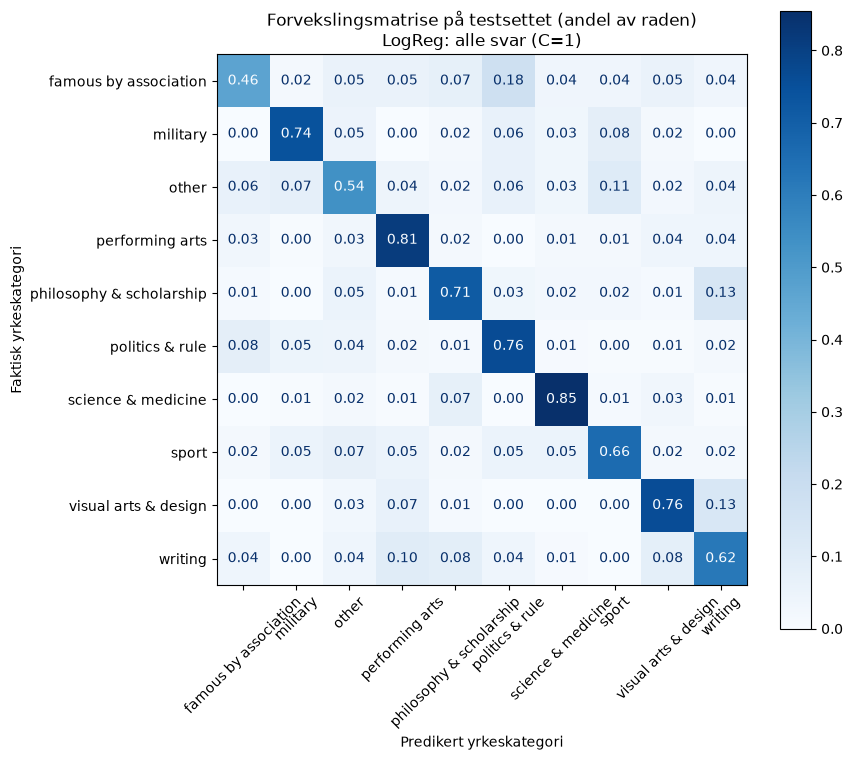

,faktisk,predikert,andel
5,famous by association,politics & rule,0.179
49,philosophy & scholarship,writing,0.134
89,visual arts & design,writing,0.133
27,other,sport,0.105
93,writing,performing arts,0.100
94,writing,philosophy & scholarship,0.085
50,politics & rule,famous by association,0.081
17,military,sport,0.081


In [47]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, test_pred, labels=labels, normalize="true")

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45, colorbar=True)
ax.set_xlabel("Predikert yrkeskategori")
ax.set_ylabel("Faktisk yrkeskategori")
ax.set_title(f"Forvekslingsmatrise på testsettet (andel av raden)\n{best_name_b}")
plt.tight_layout()
plt.savefig("img/forvekslingsmatrise.png", dpi=200, bbox_inches="tight")
plt.show()

# The most frequent confusions (off-diagonal cells)
confusions = (pd.DataFrame(cm, index=labels, columns=labels).stack().rename_axis(["faktisk", "predikert"]).reset_index(name="andel"))
confusions = confusions[confusions["faktisk"] != confusions["predikert"]]
confusions.sort_values("andel", ascending=False).head(8).round(3)

Feilene følger meningsfulle grenser mellom yrker: `famous by association` →
`politics & rule` (kongelige og ektefeller til statsledere), og `philosophy &
scholarship` og `visual arts & design` → `writing` (beslektede kulturyrker).

### 11.6 Hvilke ord forbinder modellen med hvert yrke?

Når den valgte modellen er lineær (logistisk regresjon eller SGD), har hver klasse en
koeffisient per variabel. Vi viser ordene (TF-IDF) med høyest koeffisient for hver
klasse. Dette er bare tolkning. Testsettet er allerede brukt, og ingenting endres.

In [48]:
model_b = final_model_b.named_steps["model"]
if hasattr(model_b, "coef_"):
    names = final_model_b.named_steps["prep"].get_feature_names_out()
    is_word = np.char.startswith(names.astype(str), "text__")
    top_words_b = {}
    for cls, coefs in zip(model_b.classes_, model_b.coef_):
        best = np.argsort(coefs[is_word])[::-1][:8]
        top_words_b[cls] = ", ".join(w.replace("text__", "") for w in names[is_word][best])
    display(pd.Series(top_words_b, name="ord med høyest koeffisient").to_frame())
else:
    print("Den valgte modellen er ikke lineær, så den har ingen koeffisienter per ord.")

,ord med høyest koeffisient
famous by association,"swan, king, numbers, venus, figs, prometheus, ..."
military,"enemy, war, rugged, art, lawrence, strategic, ..."
other,"market, systemic, tides, albatross, predict, c..."
performing arts,"melody, steak, emotion, music, dramatic, beeth..."
philosophy & scholarship,"athens, school, linguistic, eagle, adam, cultu..."
politics & rule,"prince, maritime, trends, coronation, analysis..."
science & medicine,"biological, falcon, chemical, principia, mathe..."
sport,"art, player, war, starry, mountains, movement,..."
visual arts & design,"moody, light, structural, dramatic, geometry, ..."
writing,"clinging, human, behavior, persistent, dostoev..."


## 12. Endelige resultater

Tabellen bygges fra variablene over, slik at den alltid stemmer med kjøringen.

In [49]:
final_results = pd.DataFrame([
    {"oppgave": "A: fødselsår (regresjon)", "valgt modell": best_name_a,
     "validering": f"MAE {results_a_df.iloc[0]['MAE']:.1f} år",
     "test": f"MAE {test_mae_a:.1f} år, medianfeil {test_median_a:.1f} år"},
    
    {"oppgave": "B: yrkeskategori (klassifikasjon)", "valgt modell": best_name_b,
     "validering": f"balanced accuracy {results_b_df.iloc[0]['balanced_accuracy']:.3f}",
     "test": f"balanced accuracy {test_bacc_b:.3f}, makro-F1 {test_f1_b:.3f}"},
])
final_results

,oppgave,valgt modell,validering,test
0,A: fødselsår (regresjon),RF: alle svar (300 ord),MAE 304.1 år,"MAE 285.2 år, medianfeil 94.2 år"
1,B: yrkeskategori (klassifikasjon),LogReg: alle svar (C=1),balanced accuracy 0.743,"balanced accuracy 0.692, makro-F1 0.662"
